## **Cell 0: Environment Setup & Dependency Installation**
> **Note:** Run this cell once to install necessary packages (such as `google-genai`, `scikit-learn` and `seaborn`) if they are missing in your environment.

In [ ]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn google-genai

## **Cell 1: Import Libraries and Configuration**
Import essential Python modules for regex processing, timing, data handling, visualization, dataset downloading, and machine learning metric evaluation.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully.")

Libraries imported successfully.


## **Cell 2: Download and Load the Dataset**
Downloads the Financial PhraseBank dataset via Google Colab

In [ ]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))

Saving all-data.csv to all-data.csv
Uploaded files: ['all-data.csv']


In [ ]:
import os

print("Files in the working directory:")
print(os.listdir("/content"))

Files in the working directory:
['.config', 'all-data.csv', 'sample_data']


# **Cell 3: Load and inspect the raw dataset**




In [ ]:
# Load the raw dataset
df = pd.read_csv(
    "/content/all-data.csv",
    encoding="latin-1",
    header=None,
    names=["sentiment", "text"]
)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (4846, 2)

First 5 rows:


,sentiment,text
0,neutral,"According to Gran , the company has no plans t..."
1,neutral,Technopolis plans to develop in stages an area...
2,negative,The international electronic industry company ...
3,positive,With the new production plant the company woul...
4,positive,According to the company 's updated strategy f...



Column names:
['sentiment', 'text']

Data types:
sentiment    object
text         object
dtype: object

Missing values:
sentiment    0
text         0
dtype: int64


# **Cell 4: Check the labels and data quality**



In [ ]:
print("Sentiment distribution:")
print(df["sentiment"].value_counts(dropna=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nEmpty or whitespace-only sentences:")
print(
    df["text"].isna().sum()
    + df["text"].fillna("").str.strip().eq("").sum()
)

print("\nSample sentences:")
for _, row in df.sample(min(5, len(df)), random_state=42).iterrows():
    print(f"\nSentiment: {row['sentiment']}")
    print(f"Text: {row['text']}")

Sentiment distribution:
sentiment
neutral     2879
positive    1363
negative     604
Name: count, dtype: int64

Duplicate rows: 6

Empty or whitespace-only sentences:
0

Sample sentences:

Sentiment: neutral
Text: The company was supposed to deliver machinery to a veneer mill in the Tomsk region , in Russia .

Sentiment: neutral
Text: UNC Charlotte would also deploy SSH Tectia Connector to enable secure application connectivity .

Sentiment: neutral
Text: In 2009 , Lee & Man had a combined annual production capacity of close to 4.5 million tonnes of paper and 300,000 tonnes of pulp .

Sentiment: neutral
Text: `` That 's a very high figure on the European scale , '' Noop said , recalling however that this also includes beer bought by Finnish tourists .

Sentiment: neutral
Text: In Finland , the corresponding service is Alma Media 's Etuovi.com , Finland 's most popular and best known nationwide online service for home and property sales .


**Preprocessing**


1.   Remove exact duplicate rows after inspecting their labels.
2.  Strip leading and trailing whitespace.
3. Remove rows with missing or empty text, if any appear in further checks
4. Normalize label casing and verify the three expected classes.
5. Preserve punctuation, negation, numbers, financial figures and the original sentence wording.




Find and remove duplicate rows

In [ ]:
# Display every exact duplicate row, including its first occurrence
duplicate_mask = df.duplicated(keep=False)

duplicate_rows = (
    df.loc[duplicate_mask]
      .sort_values(["sentiment", "text"])
)

print("Rows involved in exact duplicates:", len(duplicate_rows))
display(duplicate_rows)

Rows involved in exact duplicates: 12


,sentiment,text
2395,neutral,Ahlstrom 's share is quoted on the NASDAQ OMX ...
2396,neutral,Ahlstrom 's share is quoted on the NASDAQ OMX ...
3093,neutral,Proha Plc ( Euronext :7327 ) announced today (...
3094,neutral,Proha Plc ( Euronext :7327 ) announced today (...
2566,neutral,SSH Communications Security Corporation is hea...
2567,neutral,SSH Communications Security Corporation is hea...
3205,neutral,The company serves customers in various indust...
3206,neutral,The company serves customers in various indust...
1098,neutral,The issuer is solely responsible for the conte...
1099,neutral,The issuer is solely responsible for the conte...


In [ ]:
# Preserve the original dataframe for reference
df_raw = df.copy()

# Conservative text and label normalization
df["sentiment"] = df["sentiment"].str.strip().str.lower()
df["text"] = df["text"].str.strip()

# Remove missing and empty records
df = df.dropna(subset=["sentiment", "text"])
df = df[
    df["text"].ne("") &
    df["sentiment"].ne("")
].copy()

# Remove exact duplicate sentence-label records
df = df.drop_duplicates(
    subset=["sentiment", "text"]
).reset_index(drop=True)

# Validate expected labels
expected_labels = {"positive", "negative", "neutral"}

assert set(df["sentiment"].unique()) == expected_labels
assert df["text"].notna().all()
assert df["text"].str.len().gt(0).all()
assert not df.duplicated(subset=["sentiment", "text"]).any()

print("Cleaned dataset shape:", df.shape)
print("\nClass distribution:")
print(df["sentiment"].value_counts())

print("\nRemaining missing values:")
print(df.isna().sum())

print("\nRemaining duplicate sentence-label pairs:",
      df.duplicated(subset=["sentiment", "text"]).sum())

Cleaned dataset shape: (4840, 2)

Class distribution:
sentiment
neutral     2873
positive    1363
negative     604
Name: count, dtype: int64

Remaining missing values:
sentiment    0
text         0
dtype: int64

Remaining duplicate sentence-label pairs: 0


Find and remove rows with confilcting labels


In [ ]:
# Find sentences associated with more than one sentiment label
label_counts_per_text = df.groupby("text")["sentiment"].nunique()

conflicting_texts = label_counts_per_text[
    label_counts_per_text > 1
].index

conflicts_df = (
    df[df["text"].isin(conflicting_texts)]
    .sort_values("text")
)

print("Number of sentences with conflicting labels:",
      len(conflicting_texts))

print("Number of rows involved in conflicts:",
      len(conflicts_df))

display(conflicts_df)

Number of sentences with conflicting labels: 2
Number of rows involved in conflicts: 4


,sentiment,text
78,neutral,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sel...
79,positive,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sel...
788,positive,The Group 's business is balanced by its broad...
789,neutral,The Group 's business is balanced by its broad...


In [ ]:
# Create a temporary comparison key; do not modify the actual text
normalized_text = (
    df["text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

normalized_groups = df.assign(
    _normalized_text=normalized_text
)

normalized_conflicts = (
    normalized_groups.groupby("_normalized_text")["sentiment"]
    .nunique()
)

normalized_conflicts = normalized_conflicts[
    normalized_conflicts > 1
]

print(
    "Whitespace-normalized sentences with conflicting labels:",
    len(normalized_conflicts)
)

Whitespace-normalized sentences with conflicting labels: 2


In [ ]:
# remove these two ambiguous sentences

In [ ]:
# Remove sentences that have more than one sentiment label
df_model = df[~df["text"].isin(conflicting_texts)].copy()

df_model = df_model.reset_index(drop=True)

print("Original cleaned dataset:", df.shape)
print("Dataset after conflict removal:", df_model.shape)

print("\nClass distribution:")
print(df_model["sentiment"].value_counts())

print("\nClass proportions:")
print(
    (df_model["sentiment"].value_counts(normalize=True) * 100)
    .round(2)
)

Original cleaned dataset: (4840, 2)
Dataset after conflict removal: (4836, 2)

Class distribution:
sentiment
neutral     2871
positive    1361
negative     604
Name: count, dtype: int64

Class proportions:
sentiment
neutral     59.37
positive    28.14
negative    12.49
Name: proportion, dtype: float64


In [ ]:
# Normalize whitespace for duplicate detection only
normalized_text = (
    df_model["text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df_model = df_model.assign(
    _normalized_text=normalized_text
)

print(
    "Rows with repeated normalized text:",
    df_model.duplicated(
        subset=["_normalized_text"],
        keep=False
    ).sum()
)

print(
    "Unique normalized sentences:",
    df_model["_normalized_text"].nunique()
)

print(
    "Rows with conflicting labels remaining:",
    (
        df_model.groupby("_normalized_text")["sentiment"]
        .nunique()
        .gt(1)
        .sum()
    )
)

Rows with repeated normalized text: 0
Unique normalized sentences: 4836
Rows with conflicting labels remaining: 0


# **Cell 5: Explore the dataset visually (EDA)**
1. Sentiment distribution.



2. Sentence length distribution.



3. Average word count by sentiment.



4. Most frequent words (without removing stopwords or changing the original text).

In [ ]:
# Count words in each financial sentence
df_model["word_count"] = df_model["text"].apply(
    lambda sentence: len(sentence.split())
)

# Count characters
df_model["char_count"] = df_model["text"].str.len()

# View statistical summary
display(
    df_model.groupby("sentiment")[
        ["word_count", "char_count"]
    ].describe().round(2)
)

word_count                                            char_count  \
               count   mean    std  min   25%   50%   75%   max      count   
sentiment                                                                    
negative       604.0  23.92   9.89  5.0  17.0  22.0  30.0  56.0      604.0   
neutral       2871.0  22.15   9.78  2.0  15.0  21.0  28.0  81.0     2871.0   
positive      1361.0  24.68  10.06  5.0  17.0  23.0  31.0  57.0     1361.0   

                                                           
             mean    std   min   25%    50%    75%    max  
sentiment                                                  
negative   125.76  52.90  37.0  85.0  118.0  157.0  296.0  
neutral    124.94  56.86   9.0  81.0  116.0  161.0  315.0  
positive   135.60  56.24  24.0  91.0  128.0  175.0  298.0

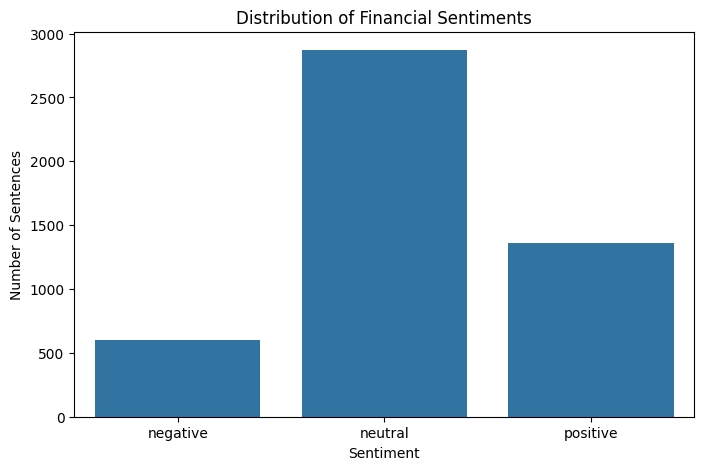

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_model,
    x="sentiment",
    order=["negative", "neutral", "positive"]
)

plt.title("Distribution of Financial Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Sentences")
plt.show()

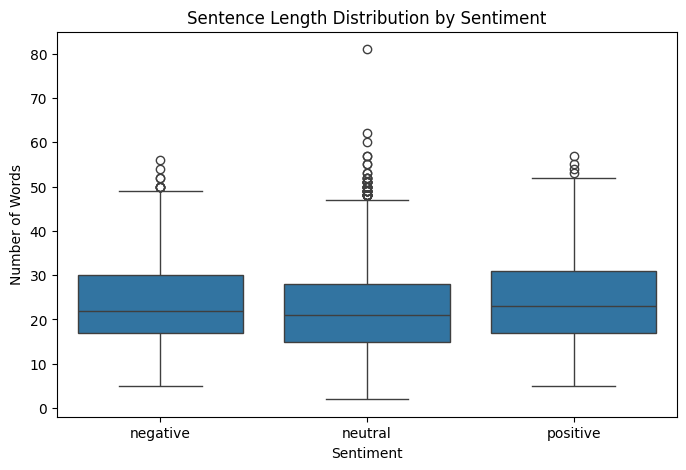

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_model,
    x="sentiment",
    y="word_count",
    order=["negative", "neutral", "positive"]
)

plt.title("Sentence Length Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.show()

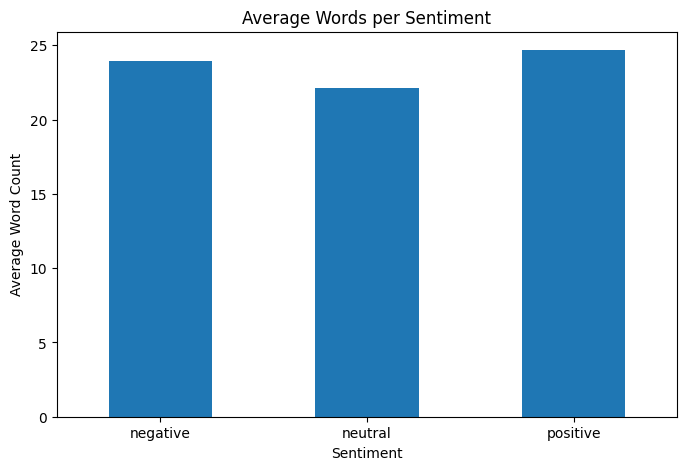

In [ ]:
average_words = (
    df_model.groupby("sentiment")["word_count"]
    .mean()
    .reindex(["negative", "neutral", "positive"])
)

average_words.plot(kind="bar", figsize=(8, 5))

plt.title("Average Words per Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Word Count")
plt.xticks(rotation=0)
plt.show()

# **Cell 6: Train, validation and test split**
**Stratified Splitting:**


So all three sets retain approximately the same sentiment proportions.


Taining 80% val 10% Test 10%

**Stratification:** Negative, neutral and positive sentences are represented in similar proportions across all three datasets. This makes the evaluation more dependable.

**No leakage**: No normalized sentence appears in more than one split. Therefore, Gemini cannot simply encounter a sentence during training-example selection and then see that same sentence in the test set.

In [ ]:
# First split: 80% training, 20% temporary
train_df, temp_df = train_test_split(
    df_model,
    test_size=0.20,
    random_state=42,
    stratify=df_model["sentiment"]
)

# Second split: divide temporary data equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["sentiment"]
)

print("Training set:", train_df.shape)
print("Validation set:", val_df.shape)
print("Test set:", test_df.shape)

Training set: (3868, 5)
Validation set: (484, 5)
Test set: (484, 5)


In [ ]:
#verify the distributions
for name, split in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name} set")
    print(
        (split["sentiment"].value_counts(normalize=True) * 100)
        .round(2)
    )


Training set
sentiment
neutral     59.36
positive    28.15
negative    12.49
Name: proportion, dtype: float64

Validation set
sentiment
neutral     59.5
positive    28.1
negative    12.4
Name: proportion, dtype: float64

Test set
sentiment
neutral     59.3
positive    28.1
negative    12.6
Name: proportion, dtype: float64


In [ ]:
#verify to text leakage
train_texts = set(train_df["_normalized_text"])
val_texts = set(val_df["_normalized_text"])
test_texts = set(test_df["_normalized_text"])

print("Train-validation overlap:", len(train_texts & val_texts))
print("Train-test overlap:", len(train_texts & test_texts))
print("Validation-test overlap:", len(val_texts & test_texts))

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


# **Cell 7: Experiment A — Zero-shot: Gemini receives instructions and a financial sentence, without examples.**

In [ ]:
from google import genai
from google.genai import types
from google.colab import userdata

api_key = userdata.get("GEMINI_API_KEY")
client = genai.Client(api_key=api_key)

print("Gemini client and types imported successfully!")

Gemini client and types imported successfully!


In [ ]:
#check availabel model
for model in client.models.list():
    if "flash" in model.name.lower():
        print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts
models/gemini-2.5-flash-native-audio-latest
models/gemini-2.5-flash-native-audio-preview-09-2025
models/gemini-2.5-flash-native-audio-preview-12-2025
models/gemini-3.1-flash-live-preview


In [ ]:
response = client.models.generate_content(
    model="gemini-flash-lite-latest",
    contents=(
        "Classify this financial news sentence as positive, negative, "
        "or neutral: The company's revenue increased by 25%. "
        "Return only one label."
    ),
    config=types.GenerateContentConfig(
        temperature=0,
        max_output_tokens=20
    )
)

print("Gemini response:", response.text)

Gemini response: Positive


In [ ]:
#verify split
print("Dataset shape:", df_model.shape)
print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nTest set distribution:")
print(test_df["sentiment"].value_counts())

# Check for data leakage
train_texts = set(train_df["_normalized_text"])
val_texts = set(val_df["_normalized_text"])
test_texts = set(test_df["_normalized_text"])

print("\nTrain-Val overlap:", len(train_texts & val_texts))
print("Train-Test overlap:", len(train_texts & test_texts))
print("Val-Test overlap:", len(val_texts & test_texts))

Dataset shape: (4836, 5)
Training shape: (3868, 5)
Validation shape: (484, 5)
Test shape: (484, 5)

Test set distribution:
sentiment
neutral     287
positive    136
negative     61
Name: count, dtype: int64

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [ ]:
#prepare few-shot examples
few_shot_examples = pd.concat([
    train_df[train_df["sentiment"] == label].sample(
        n=2, random_state=42
    )
    for label in ["negative", "neutral", "positive"]
]).reset_index(drop=True)

display(few_shot_examples[["sentiment", "text"]])

print("Total examples:", len(few_shot_examples))
print(few_shot_examples["sentiment"].value_counts())

,sentiment,text
0,negative,"Operating result showed a loss of EUR 2.9 mn ,..."
1,negative,18 March 2010 A leakage in the gypsum pond was...
2,neutral,"In 2007 , Etteplan had turnover of EUR125 .2 m."
3,neutral,The company was supposed to deliver machinery ...
4,positive,Rautaruukki said construction group YIT has aw...
5,positive,28 October 2010 - Finnish wood products techno...


Total examples: 6
sentiment
negative    2
neutral     2
positive    2
Name: count, dtype: int64


In [ ]:
#Gemini zero-shot piolt
import json
from google.genai import types

GEMINI_MODEL = "gemini-flash-lite-latest"
BATCH_SIZE = 10

SYSTEM_PROMPT = """
You are an expert financial sentiment classification system.

Classify each financial news sentence into exactly one category:
positive, negative, or neutral.

Consider the financial meaning and context.

Return ONLY a valid JSON array containing one lowercase
sentiment label for each input sentence.

Do not include explanations or additional text.
"""

# Use 10 validation sentences for the pilot
pilot_df = val_df.head(10).copy()

sentences = pilot_df["text"].tolist()

prompt = (
    SYSTEM_PROMPT
    + "\n\nClassify these sentences:\n"
    + json.dumps(sentences, ensure_ascii=False)
)

response = client.models.generate_content(
    model=GEMINI_MODEL,
    contents=prompt,
    config=types.GenerateContentConfig(
        temperature=0,
        max_output_tokens=150,
        response_mime_type="application/json"
    )
)

print("Raw Gemini response:")
print(response.text)

Raw Gemini response:
[
  "negative",
  "neutral",
  "neutral",
  "neutral",
  "positive",
  "negative",
  "neutral",
  "positive",
  "neutral",
  "neutral"
]


In [ ]:
#validate response
pilot_predictions = json.loads(response.text)

valid_labels = {"positive", "negative", "neutral"}

print("Number of input sentences:", len(sentences))
print("Number of predictions:", len(pilot_predictions))
print("All labels valid:",
      all(label in valid_labels for label in pilot_predictions))

print("\nPredictions:")
for i, (sentence, prediction) in enumerate(
    zip(sentences, pilot_predictions), 1
):
    print(f"{i}. {prediction} | {sentence[:100]}")

Number of input sentences: 10
Number of predictions: 10
All labels valid: True

Predictions:
1. negative | Vanhanen said the strike would be `` extremely damaging '' as some 1,300 participants and reporters 
2. neutral | Tulikivi manufactures heat-retaining , soapstone and ceramic fireplaces , as well as natural stone p
3. neutral | `` The biggest challenge was to make the piece look raw , '' Hansen said .
4. neutral | According to business media reports , Usmanov planned to transfer his MegaFon stake to the state-con
5. positive | The new factory working model and reorganisations would decrease Nokian Tyres ' costs in the factory
6. negative | Nokia 's share price fell less than one percent to 18.70 euros ( $ 25.41 ) in Helsinki , while Sieme
7. neutral | The Estonian parliament was set to vote on amendments to the excise duty law on Wednesday that would
8. positive | Solvay S.A. has engaged Poyry to provide project management , engineering , procurement , and site s
9. neutral | Insu

Run Gemini zero-shot on all 484 test samples

- Model: gemini-flash-lite-latest
- Temperature: 0
- Batch size: 10
- Expected API calls: approximately 49
- Automatic checkpoint saving after every successful batch.
- Resume support if Colab disconnects.

In [ ]:
#zero shot
import os
import json
import time
import pandas as pd
from google.genai import types

# Configuration
GEMINI_MODEL = "gemini-flash-lite-latest"
BATCH_SIZE = 10
MAX_RETRIES = 3

OUTPUT_FILE = "/content/gemini_zero_shot_predictions.csv"

VALID_LABELS = {"positive", "negative", "neutral"}

SYSTEM_PROMPT = """
You are an expert financial sentiment classification system.

Classify each financial news sentence into exactly one category:
positive, negative, or neutral.

Consider the financial meaning and context.

Rules:
1. Return exactly one label for each sentence.
2. Preserve the original sentence order.
3. Use lowercase labels only.
4. Do not provide explanations.
5. Return ONLY a valid JSON array.
"""

# Reset test dataframe indexing for consistent checkpoint IDs
gemini_test_df = test_df.reset_index(drop=True).copy()

# Restore completed predictions if a checkpoint exists
if os.path.exists(OUTPUT_FILE):
    results_df = pd.read_csv(OUTPUT_FILE)
    completed_indices = set(results_df["test_index"].tolist())
    print("Resuming from existing checkpoint.")
else:
    results_df = pd.DataFrame(columns=[
        "test_index",
        "true_label",
        "prediction",
        "raw_response"
    ])
    completed_indices = set()

print("Already completed:", len(completed_indices))
print("Remaining:", len(gemini_test_df) - len(completed_indices))

# Process remaining sentences in batches
for start in range(0, len(gemini_test_df), BATCH_SIZE):

    batch_indices = [
        i for i in range(
            start,
            min(start + BATCH_SIZE, len(gemini_test_df))
        )
        if i not in completed_indices
    ]

    if not batch_indices:
        continue

    batch_texts = [
        gemini_test_df.iloc[i]["text"]
        for i in batch_indices
    ]

    prompt = (
        SYSTEM_PROMPT
        + "\n\nClassify these financial news sentences:\n"
        + json.dumps(batch_texts, ensure_ascii=False)
    )

    success = False

    for attempt in range(MAX_RETRIES):

        try:
            response = client.models.generate_content(
                model=GEMINI_MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0,
                    max_output_tokens=200,
                    response_mime_type="application/json"
                )
            )

            raw_response = response.text.strip()
            predictions = json.loads(raw_response)

            # Validate output
            if not isinstance(predictions, list):
                raise ValueError("Response is not a JSON list.")

            if len(predictions) != len(batch_indices):
                raise ValueError("Prediction count mismatch.")

            predictions = [
                str(p).strip().lower()
                for p in predictions
            ]

            if not all(p in VALID_LABELS for p in predictions):
                raise ValueError("Invalid sentiment label detected.")

            # Save successful batch
            batch_results = pd.DataFrame({
                "test_index": batch_indices,
                "true_label": [
                    gemini_test_df.iloc[i]["sentiment"]
                    for i in batch_indices
                ],
                "prediction": predictions,
                "raw_response": [raw_response] * len(batch_indices)
            })

            results_df = pd.concat(
                [results_df, batch_results],
                ignore_index=True
            )

            results_df = results_df.sort_values(
                "test_index"
            ).reset_index(drop=True)

            results_df.to_csv(OUTPUT_FILE, index=False)

            completed_indices.update(batch_indices)
            success = True

            print(
                f"Completed {len(completed_indices)}/"
                f"{len(gemini_test_df)}"
            )

            break

        except Exception as e:
            print(
                f"Batch starting at {start}: "
                f"Attempt {attempt + 1} failed: {e}"
            )

            if attempt < MAX_RETRIES - 1:
                time.sleep(30 * (attempt + 1))

    if not success:
        print("\nStopping to protect remaining quota.")
        print("Successful batches have been saved.")
        break

    # Small pause between successful requests
    time.sleep(2)

print("\nExperiment progress:")
print("Completed predictions:", len(completed_indices))
print("Remaining predictions:", len(gemini_test_df) - len(completed_indices))
print("Saved file:", OUTPUT_FILE)

Already completed: 0
Remaining: 484
Completed 10/484
Completed 20/484
Completed 30/484
Completed 40/484
Completed 50/484
Completed 60/484
Completed 70/484
Completed 80/484
Completed 90/484
Completed 100/484
Completed 110/484
Completed 120/484
Completed 130/484
Completed 140/484
Completed 150/484
Completed 160/484
Completed 170/484
Completed 180/484
Completed 190/484
Completed 200/484
Completed 210/484
Completed 220/484
Completed 230/484
Completed 240/484
Completed 250/484
Completed 260/484
Completed 270/484
Completed 280/484
Batch starting at 280: Attempt 1 failed: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 15, model: gemini-3

In [ ]:
import pandas as pd

OUTPUT_FILE = "/content/gemini_zero_shot_predictions.csv"

gemini_results = pd.read_csv(OUTPUT_FILE)

print("Total rows:", len(gemini_results))
print("Unique test indices:", gemini_results["test_index"].nunique())
print("Missing predictions:", gemini_results["prediction"].isna().sum())
print("Duplicate indices:", gemini_results["test_index"].duplicated().sum())

valid_labels = {"positive", "negative", "neutral"}

print(
    "Invalid predictions:",
    (~gemini_results["prediction"].isin(valid_labels)).sum()
)

print("\nPrediction distribution:")
print(gemini_results["prediction"].value_counts())

assert len(gemini_results) == 484
assert gemini_results["test_index"].nunique() == 484
assert gemini_results["prediction"].notna().all()
assert gemini_results["prediction"].isin(valid_labels).all()
assert not gemini_results["test_index"].duplicated().any()

print("\nAll verification checks passed!")

Total rows: 484
Unique test indices: 484
Missing predictions: 0
Duplicate indices: 0
Invalid predictions: 0

Prediction distribution:
prediction
neutral     260
positive    154
negative     70
Name: count, dtype: int64

All verification checks passed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

y_true = gemini_results["true_label"]
y_pred = gemini_results["prediction"]

accuracy = accuracy_score(y_true, y_pred)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
)

print("GEMINI ZERO-SHOT RESULTS")
print("-" * 40)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Macro Precision:   {macro_precision:.4f}")
print(f"Macro Recall:      {macro_recall:.4f}")
print(f"Macro F1:          {macro_f1:.4f}")
print(f"Weighted Precision:{weighted_precision:.4f}")
print(f"Weighted Recall:   {weighted_recall:.4f}")
print(f"Weighted F1:       {weighted_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=["negative", "neutral", "positive"],
    zero_division=0
))

print("\nConfusion Matrix:")
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=["negative", "neutral", "positive"]
)

print(cm)

GEMINI ZERO-SHOT RESULTS
----------------------------------------
Accuracy:          0.8636
Macro Precision:   0.8375
Macro Recall:      0.8825
Macro F1:          0.8569
Weighted Precision:0.8712
Weighted Recall:   0.8636
Weighted F1:       0.8647

Classification Report:
              precision    recall  f1-score   support

    negative       0.80      0.92      0.85        61
     neutral       0.93      0.84      0.88       287
    positive       0.79      0.89      0.83       136

    accuracy                           0.86       484
   macro avg       0.84      0.88      0.86       484
weighted avg       0.87      0.86      0.86       484


Confusion Matrix:
[[ 56   4   1]
 [ 14 241  32]
 [  0  15 121]]


In [ ]:
metrics_df = pd.DataFrame([{
    "model": GEMINI_MODEL,
    "method": "zero-shot",
    "accuracy": accuracy,
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1": macro_f1,
    "weighted_precision": weighted_precision,
    "weighted_recall": weighted_recall,
    "weighted_f1": weighted_f1
}])

metrics_df.to_csv(
    "/content/gemini_zero_shot_metrics.csv",
    index=False
)

print("Metrics saved successfully!")

Metrics saved successfully!


Few shot with 6 examples

In [ ]:
#verify 6 examples for few shot
few_shot_examples = pd.concat([
    train_df[train_df["sentiment"] == label].sample(
        n=2, random_state=42
    )
    for label in ["negative", "neutral", "positive"]
]).reset_index(drop=True)

display(few_shot_examples[["sentiment", "text"]])

print("\nExample distribution:")
print(few_shot_examples["sentiment"].value_counts())

,sentiment,text
0,negative,"Operating result showed a loss of EUR 2.9 mn ,..."
1,negative,18 March 2010 A leakage in the gypsum pond was...
2,neutral,"In 2007 , Etteplan had turnover of EUR125 .2 m."
3,neutral,The company was supposed to deliver machinery ...
4,positive,Rautaruukki said construction group YIT has aw...
5,positive,28 October 2010 - Finnish wood products techno...



Example distribution:
sentiment
negative    2
neutral     2
positive    2
Name: count, dtype: int64


In [ ]:
#few shot prompt
FEW_SHOT_PROMPT = """
You are an expert financial sentiment classification system.

Your task is to classify financial news sentences into exactly
one of these categories:
- positive
- negative
- neutral

Here are labelled examples:

"""

# Add the six labelled examples
for _, row in few_shot_examples.iterrows():
    FEW_SHOT_PROMPT += f"""
Sentence: {row['text']}
Sentiment: {row['sentiment']}
"""

FEW_SHOT_PROMPT += """
Now classify the following sentences.

Rules:
1. Consider the financial meaning and context.
2. Return exactly one label per sentence.
3. Preserve the original order.
4. Use lowercase labels only.
5. Do not provide explanations.
6. Return ONLY a valid JSON array.
"""

print(FEW_SHOT_PROMPT)


You are an expert financial sentiment classification system.

Your task is to classify financial news sentences into exactly
one of these categories:
- positive
- negative
- neutral

Here are labelled examples:


Sentence: Operating result showed a loss of EUR 2.9 mn , while a year before , it showed a profit of EUR 0.6 mn .
Sentiment: negative

Sentence: 18 March 2010 A leakage in the gypsum pond was detected today at the Talvivaara mine .
Sentiment: negative

Sentence: In 2007 , Etteplan had turnover of EUR125 .2 m.
Sentiment: neutral

Sentence: The company was supposed to deliver machinery to a veneer mill in the Tomsk region , in Russia .
Sentiment: neutral

Sentence: Rautaruukki said construction group YIT has awarded it a 2.5 mln eur contract to supply the steel structures for a new bridge spanning the Kemijoki river in Northern Finland .
Sentiment: positive

Sentence: 28 October 2010 - Finnish wood products technology supplier Raute Oyj HEL : RUTAV said today it swung to a net 

In [ ]:
#run 10 sentence pilot
pilot_df = val_df.head(10).copy()
pilot_sentences = pilot_df["text"].tolist()

pilot_prompt = (
    FEW_SHOT_PROMPT
    + "\nSentences to classify:\n"
    + json.dumps(pilot_sentences, ensure_ascii=False)
)

response = client.models.generate_content(
    model=GEMINI_MODEL,
    contents=pilot_prompt,
    config=types.GenerateContentConfig(
        temperature=0,
        max_output_tokens=150,
        response_mime_type="application/json"
    )
)

print("Few-shot raw response:")
print(response.text)

Few-shot raw response:
[
  "negative",
  "neutral",
  "neutral",
  "neutral",
  "positive",
  "negative",
  "neutral",
  "positive",
  "neutral",
  "neutral"
]


In [ ]:
#validate the pilot
few_shot_pilot_predictions = json.loads(response.text)

valid_labels = {"positive", "negative", "neutral"}

print("Input sentences:", len(pilot_sentences))
print("Predictions:", len(few_shot_pilot_predictions))

print(
    "All labels valid:",
    all(p in valid_labels for p in few_shot_pilot_predictions)
)

assert len(few_shot_pilot_predictions) == len(pilot_sentences)
assert all(p in valid_labels for p in few_shot_pilot_predictions)

print("\nFew-shot pilot passed!")

Input sentences: 10
Predictions: 10
All labels valid: True

Few-shot pilot passed!


 Full few-shot inference
This version:
- Uses the same 484 test sentences.
- Includes the six labelled training examples.
- Uses batches of 10.
- Waits 5 seconds between successful batches to respect the 15 RPM limit we observed.
- Retries temporary errors.
- Saves every successful batch.
- Supports resuming after a disconnection.

In [ ]:
import os
import json
import time
import pandas as pd
from google.genai import types

# Configuration
GEMINI_MODEL = "gemini-flash-lite-latest"
BATCH_SIZE = 10
MAX_RETRIES = 4

OUTPUT_FILE = "/content/gemini_few_shot_predictions.csv"

VALID_LABELS = {"positive", "negative", "neutral"}

# Restore the same six labelled examples
# FEW_SHOT_PROMPT should already contain these examples
assert len(few_shot_examples) == 6

# Prepare test data
gemini_test_df = test_df.reset_index(drop=True).copy()

# Load previous checkpoint, if available
if os.path.exists(OUTPUT_FILE):
    results_df = pd.read_csv(OUTPUT_FILE)
    completed_indices = set(results_df["test_index"].tolist())
    print("Existing checkpoint restored.")
else:
    results_df = pd.DataFrame(columns=[
        "test_index",
        "true_label",
        "prediction",
        "raw_response"
    ])
    completed_indices = set()

print("Already completed:", len(completed_indices))
print("Remaining:", len(gemini_test_df) - len(completed_indices))

# Process batches
for start in range(0, len(gemini_test_df), BATCH_SIZE):

    batch_indices = [
        i for i in range(
            start,
            min(start + BATCH_SIZE, len(gemini_test_df))
        )
        if i not in completed_indices
    ]

    if not batch_indices:
        continue

    batch_texts = [
        gemini_test_df.iloc[i]["text"]
        for i in batch_indices
    ]

    prompt = (
        FEW_SHOT_PROMPT
        + "\n\nSentences to classify:\n"
        + json.dumps(batch_texts, ensure_ascii=False)
    )

    success = False

    for attempt in range(MAX_RETRIES):

        try:
            response = client.models.generate_content(
                model=GEMINI_MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0,
                    max_output_tokens=200,
                    response_mime_type="application/json"
                )
            )

            raw_response = response.text.strip()
            predictions = json.loads(raw_response)

            if not isinstance(predictions, list):
                raise ValueError("Response is not a JSON list.")

            if len(predictions) != len(batch_indices):
                raise ValueError("Prediction count mismatch.")

            predictions = [
                str(p).strip().lower()
                for p in predictions
            ]

            if not all(p in VALID_LABELS for p in predictions):
                raise ValueError("Invalid sentiment label.")

            batch_results = pd.DataFrame({
                "test_index": batch_indices,
                "true_label": [
                    gemini_test_df.iloc[i]["sentiment"]
                    for i in batch_indices
                ],
                "prediction": predictions,
                "raw_response": [raw_response] * len(batch_indices)
            })

            results_df = pd.concat(
                [results_df, batch_results],
                ignore_index=True
            )

            results_df = (
                results_df
                .drop_duplicates(subset=["test_index"], keep="last")
                .sort_values("test_index")
                .reset_index(drop=True)
            )

            results_df.to_csv(OUTPUT_FILE, index=False)

            completed_indices.update(batch_indices)
            success = True

            print(
                f"Completed {len(completed_indices)}/"
                f"{len(gemini_test_df)}"
            )

            break

        except Exception as e:
            print(
                f"Batch {start}: Attempt {attempt + 1} failed: {e}"
            )

            if attempt < MAX_RETRIES - 1:
                wait_time = 45 * (attempt + 1)
                print(f"Waiting {wait_time} seconds...")
                time.sleep(wait_time)

    if not success:
        print("Stopping. Successful batches are saved.")
        break

    # Conservative pacing for the observed free-tier limit
    time.sleep(5)

print("\nFew-shot experiment progress:")
print("Completed:", len(completed_indices))
print("Remaining:", len(gemini_test_df) - len(completed_indices))
print("Saved file:", OUTPUT_FILE)

Already completed: 0
Remaining: 484
Completed 10/484
Completed 20/484
Completed 30/484
Completed 40/484
Completed 50/484
Completed 60/484
Completed 70/484
Completed 80/484
Completed 90/484
Completed 100/484
Completed 110/484
Completed 120/484
Completed 130/484
Completed 140/484
Completed 150/484
Completed 160/484
Completed 170/484
Completed 180/484
Completed 190/484
Completed 200/484
Completed 210/484
Completed 220/484
Completed 230/484
Completed 240/484
Completed 250/484
Completed 260/484
Completed 270/484
Completed 280/484
Completed 290/484
Completed 300/484
Completed 310/484
Completed 320/484
Completed 330/484
Completed 340/484
Completed 350/484
Completed 360/484
Completed 370/484
Completed 380/484
Completed 390/484
Completed 400/484
Completed 410/484
Completed 420/484
Completed 430/484
Completed 440/484
Completed 450/484
Completed 460/484
Completed 470/484
Completed 480/484
Completed 484/484

Few-shot experiment progress:
Completed: 484
Remaining: 0
Saved file: /content/gemini_few_

In [ ]:
gemini_few_shot_results = pd.read_csv(
    "/content/gemini_few_shot_predictions.csv"
)

print("Total predictions:",
      len(gemini_few_shot_results))

print("Unique test indices:",
      gemini_few_shot_results["test_index"].nunique())

print("Missing predictions:",
      gemini_few_shot_results["prediction"].isna().sum())

print("Prediction distribution:")
print(gemini_few_shot_results["prediction"].value_counts())

assert len(gemini_few_shot_results) == 484
assert gemini_few_shot_results["test_index"].nunique() == 484
assert gemini_few_shot_results["prediction"].notna().all()
assert gemini_few_shot_results["prediction"].isin(VALID_LABELS).all()

print("\nAll verification checks passed!")

Total predictions: 484
Unique test indices: 484
Missing predictions: 0
Prediction distribution:
prediction
neutral     267
positive    143
negative     74
Name: count, dtype: int64

All verification checks passed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Actual and predicted labels
y_true = gemini_few_shot_results["true_label"]
y_pred = gemini_few_shot_results["prediction"]

# Overall accuracy
accuracy = accuracy_score(y_true, y_pred)

# Macro metrics: treats all three classes equally
macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )
)

# Weighted metrics: accounts for class distribution
weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )
)

# Display overall metrics
print("GEMINI FEW-SHOT — OVERALL PERFORMANCE")
print("-" * 45)
print(f"Accuracy:           {accuracy:.4f}")
print(f"Macro Precision:    {macro_precision:.4f}")
print(f"Macro Recall:       {macro_recall:.4f}")
print(f"Macro F1:           {macro_f1:.4f}")
print(f"Weighted Precision: {weighted_precision:.4f}")
print(f"Weighted Recall:    {weighted_recall:.4f}")
print(f"Weighted F1:        {weighted_f1:.4f}")

# Per-class performance
print("\nPER-CLASS PERFORMANCE")
print("-" * 45)
print(classification_report(
    y_true,
    y_pred,
    labels=["negative", "neutral", "positive"],
    zero_division=0,
    digits=4
))

# Confusion matrix
labels = ["negative", "neutral", "positive"]

cm = confusion_matrix(y_true, y_pred, labels=labels)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {label}" for label in labels],
    columns=[f"Predicted {label}" for label in labels]
)

print("CONFUSION MATRIX")
display(cm_df)

# Save metrics
few_shot_metrics = pd.DataFrame([{
    "Model": "Gemini Flash Lite",
    "Method": "Few-shot",
    "Accuracy": accuracy,
    "Macro Precision": macro_precision,
    "Macro Recall": macro_recall,
    "Macro F1": macro_f1,
    "Weighted Precision": weighted_precision,
    "Weighted Recall": weighted_recall,
    "Weighted F1": weighted_f1
}])

few_shot_metrics.to_csv(
    "/content/gemini_few_shot_metrics.csv",
    index=False
)

print("\nFew-shot metrics saved successfully!")

GEMINI FEW-SHOT — OVERALL PERFORMANCE
---------------------------------------------
Accuracy:           0.8574
Macro Precision:    0.8304
Macro Recall:       0.8786
Macro F1:           0.8512
Weighted Precision: 0.8625
Weighted Recall:    0.8574
Weighted F1:        0.8581

PER-CLASS PERFORMANCE
---------------------------------------------
              precision    recall  f1-score   support

    negative     0.7838    0.9508    0.8593        61
     neutral     0.9101    0.8467    0.8773       287
    positive     0.7972    0.8382    0.8172       136

    accuracy                         0.8574       484
   macro avg     0.8304    0.8786    0.8512       484
weighted avg     0.8625    0.8574    0.8581       484

CONFUSION MATRIX


,Predicted negative,Predicted neutral,Predicted positive
Actual negative,58,2,1
Actual neutral,16,243,28
Actual positive,0,22,114



Few-shot metrics saved successfully!


Few shot using 15 examples

In [ ]:
# Select 5 examples from each sentiment class
few_shot_examples_15 = pd.concat([
    train_df[train_df["sentiment"] == label].sample(
        n=5,
        random_state=42
    )
    for label in ["negative", "neutral", "positive"]
]).reset_index(drop=True)

print("Total examples:", len(few_shot_examples_15))
print("\nClass distribution:")
print(few_shot_examples_15["sentiment"].value_counts())

print("\nSelected examples:")
for _, row in few_shot_examples_15.iterrows():
    print(f"\nLabel: {row['sentiment']}")
    print(f"Text: {row['text']}")

Total examples: 15

Class distribution:
sentiment
negative    5
neutral     5
positive    5
Name: count, dtype: int64

Selected examples:

Label: negative
Text: Operating result showed a loss of EUR 2.9 mn , while a year before , it showed a profit of EUR 0.6 mn .

Label: negative
Text: 18 March 2010 A leakage in the gypsum pond was detected today at the Talvivaara mine .

Label: negative
Text: According to Finnish petrol station chain St1 's managing director Kim Wiio , the company was forced to make purchases with rising prices in the first half of 2008 , and now consumer prices are going down almost daily due to competition .

Label: negative
Text: The company plans to close two of the three lines at the plant , where some 450 jobs are under threat .

Label: negative
Text: Finnish Suominen Corporation that makes wipes , nonwovens , and flexible packaging , expects changes in the market situation to reduce sales of Suominen 's nonwovens and wet wipes from the previously estimated vol

In [ ]:
# Build the 15-example few-shot prompt

examples_text = ""

for _, row in few_shot_examples_15.iterrows():
    examples_text += (
        f"\nText: {row['text']}"
        f"\nSentiment: {row['sentiment']}\n"
    )

FEW_SHOT_PROMPT_15 = f"""
You are an expert financial news sentiment analyst.

Classify each financial news sentence into exactly one of these categories:
positive, negative, or neutral.

Here are labelled examples:

{examples_text}

Now classify the following financial news sentences.

Instructions:
1. Consider the complete financial meaning and context.
2. Do not classify based only on individual positive or negative words.
3. Return exactly one sentiment label for each input sentence.
4. Preserve the original order of the sentences.
5. Use only lowercase labels: positive, negative, neutral.
6. Do not provide explanations.
7. Return only a valid JSON array of labels.
"""
print(FEW_SHOT_PROMPT_15)


You are an expert financial news sentiment analyst.

Classify each financial news sentence into exactly one of these categories:
positive, negative, or neutral.

Here are labelled examples:


Text: Operating result showed a loss of EUR 2.9 mn , while a year before , it showed a profit of EUR 0.6 mn .
Sentiment: negative

Text: 18 March 2010 A leakage in the gypsum pond was detected today at the Talvivaara mine .
Sentiment: negative

Text: According to Finnish petrol station chain St1 's managing director Kim Wiio , the company was forced to make purchases with rising prices in the first half of 2008 , and now consumer prices are going down almost daily due to competition .
Sentiment: negative

Text: The company plans to close two of the three lines at the plant , where some 450 jobs are under threat .
Sentiment: negative

Text: Finnish Suominen Corporation that makes wipes , nonwovens , and flexible packaging , expects changes in the market situation to reduce sales of Suominen 's non

In [ ]:
# Select 10 validation sentences
pilot_texts = val_df.head(10)["text"].tolist()

response = client.models.generate_content(
    model="gemini-flash-lite-latest",
    contents=FEW_SHOT_PROMPT_15 + "\n\n" +
             "\n".join(
                 [f"{i+1}. {text}"
                  for i, text in enumerate(pilot_texts)]
             ),
    config=types.GenerateContentConfig(
        temperature=0,
        max_output_tokens=150,
        response_mime_type="application/json"
    )
)

import json

pilot_predictions_15 = json.loads(response.text)

print("Number of input sentences:", len(pilot_texts))
print("Number of predictions:", len(pilot_predictions_15))
print("\nPredictions:")
print(pilot_predictions_15)

VALID_LABELS = {"positive", "negative", "neutral"}

assert len(pilot_predictions_15) == len(pilot_texts)
assert all(p in VALID_LABELS for p in pilot_predictions_15)

print("\n15-example few-shot pilot passed!")

Number of input sentences: 10
Number of predictions: 10

Predictions:
['negative', 'neutral', 'neutral', 'neutral', 'positive', 'negative', 'neutral', 'positive', 'neutral', 'neutral']

15-example few-shot pilot passed!


In [ ]:
import os
import json
import time
import pandas as pd
from google.genai import types

GEMINI_MODEL = "gemini-flash-lite-latest"
BATCH_SIZE = 10
MAX_RETRIES = 4

OUTPUT_FILE = "/content/gemini_few_shot_15_predictions.csv"

# Load previous progress if the cell is being rerun
if os.path.exists(OUTPUT_FILE):
    results_15 = pd.read_csv(OUTPUT_FILE)
    completed_indices = set(results_15["test_index"].tolist())
else:
    results_15 = pd.DataFrame(columns=[
        "test_index", "true_label", "prediction", "raw_response"
    ])
    completed_indices = set()

print("Already completed:", len(completed_indices))

# Prepare remaining test samples
remaining_df = test_df[
    ~test_df.index.isin(completed_indices)
].copy()

for start in range(0, len(remaining_df), BATCH_SIZE):

    batch = remaining_df.iloc[start:start+BATCH_SIZE]

    batch_texts = batch["text"].tolist()

    numbered_texts = "\n".join(
        [f"{i+1}. {text}" for i, text in enumerate(batch_texts)]
    )

    prompt = (
        FEW_SHOT_PROMPT_15
        + "\n\nSentences to classify:\n"
        + numbered_texts
    )

    success = False

    for attempt in range(MAX_RETRIES):

        try:
            response = client.models.generate_content(
                model=GEMINI_MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0,
                    max_output_tokens=200,
                    response_mime_type="application/json"
                )
            )

            predictions = json.loads(response.text)

            if (
                not isinstance(predictions, list)
                or len(predictions) != len(batch)
                or not all(p in VALID_LABELS for p in predictions)
            ):
                raise ValueError("Invalid prediction format or labels")

            new_rows = pd.DataFrame({
                "test_index": batch.index.tolist(),
                "true_label": batch["sentiment"].tolist(),
                "prediction": predictions,
                "raw_response": [response.text] * len(batch)
            })

            results_15 = pd.concat(
                [results_15, new_rows],
                ignore_index=True
            )

            # Save checkpoint after every successful batch
            results_15.to_csv(OUTPUT_FILE, index=False)

            success = True

            print(
                f"Completed: {len(results_15)}/484"
            )

            break

        except Exception as e:
            wait_time = 45 * (attempt + 1)

            print(
                f"Attempt {attempt+1} failed: {e}"
            )

            if attempt < MAX_RETRIES - 1:
                print(f"Waiting {wait_time} seconds...")
                time.sleep(wait_time)

    if not success:
        print("Batch failed after retries. Stopping safely.")
        break

    time.sleep(5)

print("\nExperiment progress:")
print("Completed predictions:", len(results_15))
print("Remaining predictions:", 484 - len(results_15))
print("Saved file:", OUTPUT_FILE)

Already completed: 0
Completed: 10/484
Completed: 20/484
Completed: 30/484
Completed: 40/484
Completed: 50/484
Completed: 60/484
Completed: 70/484
Completed: 80/484
Completed: 90/484
Completed: 100/484
Completed: 110/484
Completed: 120/484
Completed: 130/484
Completed: 140/484
Completed: 150/484
Completed: 160/484
Completed: 170/484
Completed: 180/484
Completed: 190/484
Completed: 200/484
Completed: 210/484
Completed: 220/484
Completed: 230/484
Completed: 240/484
Completed: 250/484
Completed: 260/484
Completed: 270/484
Completed: 280/484
Completed: 290/484
Completed: 300/484
Completed: 310/484
Completed: 320/484
Attempt 1 failed: Invalid prediction format or labels
Waiting 45 seconds...
Attempt 2 failed: Invalid prediction format or labels
Waiting 90 seconds...
Attempt 3 failed: Invalid prediction format or labels
Waiting 135 seconds...
Attempt 4 failed: Invalid prediction format or labels
Batch failed after retries. Stopping safely.

Experiment progress:
Completed predictions: 320
Rem

In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/gemini_few_shot_15_predictions.csv"
)

print(df.shape)
print(df.tail())
print(df.isnull().sum())

(320, 4)
     test_index true_label prediction  \
315        4006   negative   negative   
316        1577    neutral    neutral   
317        2694    neutral    neutral   
318         922   positive   positive   
319        3749    neutral    neutral   

                                          raw_response  
315  [\n  "positive",\n  "neutral",\n  "neutral",\n...  
316  [\n  "positive",\n  "neutral",\n  "neutral",\n...  
317  [\n  "positive",\n  "neutral",\n  "neutral",\n...  
318  [\n  "positive",\n  "neutral",\n  "neutral",\n...  
319  [\n  "positive",\n  "neutral",\n  "neutral",\n...  
test_index      0
true_label      0
prediction      0
raw_response    0
dtype: int64


In [ ]:

# ============================================================
# GEMINI 15-SHOT FINANCIAL SENTIMENT ANALYSIS
# RESUMABLE EXPERIMENT WITH ROBUST ERROR HANDLING
# ============================================================

import os
import json
import time
import pandas as pd
from google.genai import types

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

GEMINI_MODEL = "gemini-flash-lite-latest"

BATCH_SIZE = 10
MAX_RETRIES = 4

OUTPUT_FILE = "/content/gemini_few_shot_15_predictions.csv"
ERROR_FILE = "/content/gemini_few_shot_15_errors.csv"

VALID_LABELS = ["positive", "negative", "neutral"]

print("Starting Gemini 15-shot experiment...")


# ------------------------------------------------------------
# 2. VERIFY FEW-SHOT EXAMPLES
# ------------------------------------------------------------

print("\nChecking few-shot examples...")

assert len(few_shot_examples_15) == 15, (
    "Expected exactly 15 few-shot examples."
)

# Check balanced class distribution
class_counts = few_shot_examples_15["sentiment"].value_counts()

print("\nFew-shot class distribution:")
print(class_counts)

for label in VALID_LABELS:
    assert class_counts.get(label, 0) == 5, (
        f"Expected 5 examples for {label}."
    )

# Verify all examples come from training data
assert few_shot_examples_15.index.isin(train_df.index).all(), (
    "Data leakage detected! Some few-shot examples "
    "are not from train_df."
)

print("\nVerified:")
print("5 Positive examples")
print("5 Negative examples")
print("5 Neutral examples")
print("All examples belong to training data.")


# ------------------------------------------------------------
# 3. BUILD FEW-SHOT PROMPT
# ------------------------------------------------------------

examples_text = ""

for _, row in few_shot_examples_15.iterrows():

    examples_text += (
        f"\nText: {row['text']}"
        f"\nSentiment: {row['sentiment']}\n"
    )


FEW_SHOT_PROMPT_15 = f"""
You are an expert financial news sentiment analyst.

Classify each financial news sentence into exactly one
of these categories:

positive, negative, or neutral.

Here are labelled examples:

{examples_text}

Now classify the following financial news sentences.

Classification guidelines:

1. Consider the complete financial meaning and context.
2. Do not classify based only on individual positive
   or negative words.
3. Positive: favourable financial or business implications.
4. Negative: unfavourable financial or business implications.
5. Neutral: factual statements without clear positive
   or negative sentiment.

Output requirements:

1. Return exactly one label for every input sentence.
2. Preserve the original input order.
3. Use only lowercase labels:
   positive, negative, neutral.
4. Every label must be a JSON string.
5. Return exactly one JSON array.
6. Do not include explanations.
7. Do not include markdown code fences.
8. Do not skip any sentence.

Example output:
["positive", "negative", "neutral"]
"""

print("\nFew-shot prompt successfully created.")


# ------------------------------------------------------------
# 4. LOAD PREVIOUS CHECKPOINT
# ------------------------------------------------------------

if os.path.exists(OUTPUT_FILE):

    results_15 = pd.read_csv(OUTPUT_FILE)

    print("\nPrevious checkpoint found.")

    # Remove duplicate indices, retaining the latest row
    results_15 = results_15.drop_duplicates(
        subset=["test_index"],
        keep="last"
    )

else:

    results_15 = pd.DataFrame(columns=[
        "test_index",
        "true_label",
        "prediction",
        "raw_response"
    ])

    print("\nNo previous checkpoint found. Starting fresh.")


# Convert indices to a consistent format for comparison
completed_indices = set(
    results_15["test_index"].astype(str).tolist()
)

print("\nAlready completed:", len(completed_indices))


# ------------------------------------------------------------
# 5. PREPARE REMAINING TEST SAMPLES
# ------------------------------------------------------------

remaining_df = test_df[
    ~test_df.index.astype(str).isin(completed_indices)
].copy()

TOTAL = len(test_df)

print("Total test samples:", TOTAL)
print("Completed predictions:", len(results_15))
print("Remaining predictions:", len(remaining_df))


# ------------------------------------------------------------
# 6. FUNCTION TO PARSE AND VALIDATE GEMINI RESPONSE
# ------------------------------------------------------------

def validate_predictions(raw_response, expected_count):

    if not raw_response:
        raise ValueError("Gemini returned an empty response.")

    # Parse JSON
    predictions = json.loads(raw_response)

    # Check whether response is a list
    if not isinstance(predictions, list):

        raise ValueError(
            f"Expected JSON list, received "
            f"{type(predictions).__name__}"
        )

    # Check prediction count
    if len(predictions) != expected_count:

        raise ValueError(
            f"Expected {expected_count} predictions, "
            f"received {len(predictions)}"
        )

    # Normalize simple formatting differences
    predictions = [
        str(p).strip().lower().strip(" .,:;")
        if isinstance(p, str) else p
        for p in predictions
    ]

    # Check labels
    invalid_labels = [
        p for p in predictions
        if p not in VALID_LABELS
    ]

    if invalid_labels:

        raise ValueError(
            f"Invalid sentiment labels: {invalid_labels}"
        )

    return predictions


# ------------------------------------------------------------
# 7. FUNCTION TO SAVE CHECKPOINT
# ------------------------------------------------------------

def save_checkpoint():

    results_15.to_csv(
        OUTPUT_FILE,
        index=False
    )


# ------------------------------------------------------------
# 8. FUNCTION TO SAVE FAILED ATTEMPTS
# ------------------------------------------------------------

error_records = []

def save_error(batch_indices, attempt, error, raw_response=None):

    error_records.append({
        "test_indices": str(batch_indices),
        "attempt": attempt,
        "error": str(error),
        "raw_response": str(raw_response)
    })

    pd.DataFrame(error_records).to_csv(
        ERROR_FILE,
        index=False
    )


# ------------------------------------------------------------
# 9. PROCESS TEST DATA IN BATCHES
# ------------------------------------------------------------

stop_experiment = False

for start in range(0, len(remaining_df), BATCH_SIZE):

    batch = remaining_df.iloc[
        start:start + BATCH_SIZE
    ]

    batch_texts = batch["text"].tolist()

    numbered_texts = "\n".join(
        [
            f"{i+1}. {sentence}"
            for i, sentence in enumerate(batch_texts)
        ]
    )

    prompt = (
        FEW_SHOT_PROMPT_15
        + "\n\nSentences to classify:\n"
        + numbered_texts
        + f"\n\nReturn exactly {len(batch)} labels."
    )

    success = False

    print("\n" + "=" * 55)
    print(
        f"Processing test indices: "
        f"{batch.index.tolist()}"
    )
    print("=" * 55)

    # --------------------------------------------------------
    # 10. RETRY FAILED BATCHES
    # --------------------------------------------------------

    for attempt in range(MAX_RETRIES):

        raw_response = None

        try:

            response = client.models.generate_content(

                model=GEMINI_MODEL,

                contents=prompt,

                config=types.GenerateContentConfig(

                    temperature=0,

                    max_output_tokens=300,

                    response_mime_type="application/json"
                )
            )

            raw_response = response.text

            # Display diagnostic information
            finish_reason = None

            if response.candidates:

                finish_reason = (
                    response.candidates[0].finish_reason
                )

            print("\nGemini finish reason:", finish_reason)

            print(
                "Raw response:",
                repr(raw_response)
            )

            # Validate predictions
            predictions = validate_predictions(
                raw_response,
                len(batch)
            )

            # ------------------------------------------------
            # 11. SAVE SUCCESSFUL PREDICTIONS
            # ------------------------------------------------

            new_rows = pd.DataFrame({

                "test_index": batch.index.tolist(),

                "true_label": batch["sentiment"].tolist(),

                "prediction": predictions,

                "raw_response": [
                    raw_response
                ] * len(batch)

            })

            results_15 = pd.concat(
                [results_15, new_rows],
                ignore_index=True
            )

            # Remove duplicates if any
            results_15 = results_15.drop_duplicates(
                subset=["test_index"],
                keep="last"
            )

            # Save after every successful batch
            save_checkpoint()

            success = True

            print("\nBatch successful!")

            print(
                f"Completed predictions: "
                f"{len(results_15)}/{TOTAL}"
            )

            print(
                "Remaining:",
                TOTAL - len(results_15)
            )

            break

        except Exception as e:

            wait_time = 30 * (attempt + 1)

            print(
                f"\nAttempt {attempt + 1} failed:"
            )

            print("Error:", str(e))

            save_error(
                batch.index.tolist(),
                attempt + 1,
                e,
                raw_response
            )

            if attempt < MAX_RETRIES - 1:

                print(
                    f"Retrying in {wait_time} seconds..."
                )

                time.sleep(wait_time)

    # --------------------------------------------------------
    # 12. STOP SAFELY IF ALL RETRIES FAIL
    # --------------------------------------------------------

    if not success:

        print("\nBatch failed after all retries.")

        print(
            "Stopping safely. Previous predictions "
            "remain saved."
        )

        stop_experiment = True

        break

    # Pause between successful batches
    time.sleep(5)


# ------------------------------------------------------------
# 13. FINAL EXPERIMENT STATUS
# ------------------------------------------------------------

completed_count = results_15["test_index"].nunique()

remaining_count = TOTAL - completed_count

print("\n" + "=" * 55)
print("GEMINI 15-SHOT EXPERIMENT STATUS")
print("=" * 55)

print("Total test samples:", TOTAL)

print("Completed predictions:", completed_count)

print("Remaining predictions:", remaining_count)

print(
    "Completion percentage:",
    round(completed_count / TOTAL * 100, 2),
    "%"
)

print("Predictions saved at:", OUTPUT_FILE)

if os.path.exists(ERROR_FILE):

    print("Error log saved at:", ERROR_FILE)

if remaining_count == 0:

    print("\nAll test predictions completed successfully!")

elif stop_experiment:

    print(
        "\nExperiment paused due to repeated failures."
    )

    print(
        "Rerun this cell after inspecting the error log. "
        "Previously completed predictions will be skipped."
    )

else:

    print("\nExperiment has remaining samples.")


Starting Gemini 15-shot experiment...

Checking few-shot examples...

Few-shot class distribution:
sentiment
negative    5
neutral     5
positive    5
Name: count, dtype: int64


AssertionError: Data leakage detected! Some few-shot examples are not from train_df.

In [ ]:
print("Training DataFrame:")
print("Shape:", train_df.shape)
print("Index sample:", train_df.index[:10].tolist())

print("\nFew-shot DataFrame:")
print("Shape:", few_shot_examples_15.shape)
print("Index sample:", few_shot_examples_15.index[:10].tolist())

print("\nMatching indices:",
      few_shot_examples_15.index.isin(train_df.index).sum())

print("\nMatching texts:",
      few_shot_examples_15["text"].isin(train_df["text"]).sum())

print("\nFew-shot class distribution:")
print(few_shot_examples_15["sentiment"].value_counts())

Training DataFrame:
Shape: (3868, 5)
Index sample: [4074, 4207, 4225, 618, 3635, 3404, 2672, 3969, 2598, 3804]

Few-shot DataFrame:
Shape: (15, 5)
Index sample: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Matching indices: 12

Matching texts: 15

Few-shot class distribution:
sentiment
negative    5
neutral     5
positive    5
Name: count, dtype: int64


In [ ]:
# Select 5 examples from each class in training data

few_shot_examples_15 = pd.concat([

    train_df[
        train_df["sentiment"] == "positive"
    ].sample(5, random_state=42),

    train_df[
        train_df["sentiment"] == "negative"
    ].sample(5, random_state=42),

    train_df[
        train_df["sentiment"] == "neutral"
    ].sample(5, random_state=42)

])

# Shuffle the examples
few_shot_examples_15 = few_shot_examples_15.sample(
    frac=1,
    random_state=42
)

# Reset index for convenience
few_shot_examples_15 = few_shot_examples_15.reset_index(
    drop=True
)

# Verify
print(few_shot_examples_15["sentiment"].value_counts())

print("\nTotal examples:", len(few_shot_examples_15))

sentiment
negative    5
neutral     5
positive    5
Name: count, dtype: int64

Total examples: 15


In [ ]:
# Verify that all 15 examples exist in training data

train_texts = set(train_df["text"].astype(str))

few_shot_texts = set(
    few_shot_examples_15["text"].astype(str)
)

assert few_shot_texts.issubset(train_texts), (
    "Some few-shot examples are not from training data."
)

assert len(few_shot_examples_15) == 15

assert few_shot_examples_15["sentiment"].value_counts().to_dict() == {
    "positive": 5,
    "negative": 5,
    "neutral": 5
}

print("All checks passed!")
print("15 examples verified.")
print("5 examples per sentiment class.")
print("All examples belong to training data.")

All checks passed!
15 examples verified.
5 examples per sentiment class.
All examples belong to training data.


In [ ]:
import pandas as pd
import os

OUTPUT_FILE = "/content/gemini_few_shot_15_predictions.csv"

if os.path.exists(OUTPUT_FILE):
    old_results = pd.read_csv(OUTPUT_FILE)

    print("Saved predictions:", len(old_results))
    print("\nColumns:", old_results.columns.tolist())
    print("\nFirst 5 predictions:")
    display(old_results.head())

    print("\nLast 5 predictions:")
    display(old_results.tail())
else:
    print("Checkpoint not found.")

Saved predictions: 320

Columns: ['test_index', 'true_label', 'prediction', 'raw_response']

First 5 predictions:


,test_index,true_label,prediction,raw_response
0,2028,positive,positive,"[\n ""positive"",\n ""neutral"",\n ""neutral"",\n..."
1,3536,neutral,neutral,"[\n ""positive"",\n ""neutral"",\n ""neutral"",\n..."
2,4594,neutral,neutral,"[\n ""positive"",\n ""neutral"",\n ""neutral"",\n..."
3,948,positive,positive,"[\n ""positive"",\n ""neutral"",\n ""neutral"",\n..."
4,4115,negative,negative,"[\n ""positive"",\n ""neutral"",\n ""neutral"",\n..."



Last 5 predictions:


,test_index,true_label,prediction,raw_response
315,4006,negative,negative,"[\n ""positive"",\n ""neutral"",\n ""neutral"",\n..."
316,1577,neutral,neutral,"[\n ""positive"",\n ""neutral"",\n ""neutral"",\n..."
317,2694,neutral,neutral,"[\n ""positive"",\n ""neutral"",\n ""neutral"",\n..."
318,922,positive,positive,"[\n ""positive"",\n ""neutral"",\n ""neutral"",\n..."
319,3749,neutral,neutral,"[\n ""positive"",\n ""neutral"",\n ""neutral"",\n..."


In [ ]:
print(FEW_SHOT_PROMPT_15)


You are an expert financial news sentiment analyst.

Classify each financial news sentence into exactly one of these categories:
positive, negative, or neutral.

Here are labelled examples:


Text: Operating result showed a loss of EUR 2.9 mn , while a year before , it showed a profit of EUR 0.6 mn .
Sentiment: negative

Text: 18 March 2010 A leakage in the gypsum pond was detected today at the Talvivaara mine .
Sentiment: negative

Text: According to Finnish petrol station chain St1 's managing director Kim Wiio , the company was forced to make purchases with rising prices in the first half of 2008 , and now consumer prices are going down almost daily due to competition .
Sentiment: negative

Text: The company plans to close two of the three lines at the plant , where some 450 jobs are under threat .
Sentiment: negative

Text: Finnish Suominen Corporation that makes wipes , nonwovens , and flexible packaging , expects changes in the market situation to reduce sales of Suominen 's non

In [ ]:
print("Current prompt:")
print(FEW_SHOT_PROMPT_15)

print("\nCurrent few-shot examples:")
display(
    few_shot_examples_15[["text", "sentiment"]]
)

Current prompt:

You are an expert financial news sentiment analyst.

Classify each financial news sentence into exactly one of these categories:
positive, negative, or neutral.

Here are labelled examples:


Text: Operating result showed a loss of EUR 2.9 mn , while a year before , it showed a profit of EUR 0.6 mn .
Sentiment: negative

Text: 18 March 2010 A leakage in the gypsum pond was detected today at the Talvivaara mine .
Sentiment: negative

Text: According to Finnish petrol station chain St1 's managing director Kim Wiio , the company was forced to make purchases with rising prices in the first half of 2008 , and now consumer prices are going down almost daily due to competition .
Sentiment: negative

Text: The company plans to close two of the three lines at the plant , where some 450 jobs are under threat .
Sentiment: negative

Text: Finnish Suominen Corporation that makes wipes , nonwovens , and flexible packaging , expects changes in the market situation to reduce sales of

,text,sentiment
0,Finnish Suominen Corporation that makes wipes ...,negative
1,The company was supposed to deliver machinery ...,neutral
2,Rautaruukki said construction group YIT has aw...,positive
3,"The Group , with net sales of EUR 235 million ...",neutral
4,"Operating result showed a loss of EUR 2.9 mn ,...",negative
5,The company plans to close two of the three li...,negative
6,Operating profit margin increased from 11.2 % ...,positive
7,28 October 2010 - Finnish wood products techno...,positive
8,"Also , a six-year historic analysis is provide...",neutral
9,Rautaruukki Corporation Stock exchange release...,positive


In [ ]:
#resume the few shot experiment after 320
import os
import json
import time
import pandas as pd
from google.genai import types

# Experiment settings
GEMINI_MODEL = "gemini-flash-lite-latest"
BATCH_SIZE = 10
MAX_RETRIES = 4
OUTPUT_FILE = "/content/gemini_few_shot_15_predictions.csv"

VALID_LABELS = {"positive", "negative", "neutral"}

# Load existing checkpoint
if os.path.exists(OUTPUT_FILE):
    results_15 = pd.read_csv(OUTPUT_FILE)
    completed_indices = set(results_15["test_index"].tolist())
    print("Existing predictions loaded:", len(results_15))
else:
    raise FileNotFoundError("Existing checkpoint not found!")

# Identify remaining test samples
remaining_df = test_df[
    ~test_df.index.isin(completed_indices)
].copy()

print("Already completed:", len(completed_indices))
print("Remaining:", len(remaining_df))

# Process remaining samples
for start in range(0, len(remaining_df), BATCH_SIZE):

    batch = remaining_df.iloc[start:start+BATCH_SIZE]

    numbered_texts = "\n".join(
        f"{i+1}. {text}"
        for i, text in enumerate(batch["text"].tolist())
    )

    prompt = (
        FEW_SHOT_PROMPT_15
        + "\n\nSentences to classify:\n"
        + numbered_texts
    )

    success = False

    for attempt in range(MAX_RETRIES):

        try:
            response = client.models.generate_content(
                model=GEMINI_MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0,
                    max_output_tokens=300,
                    response_mime_type="application/json"
                )
            )

            predictions = json.loads(response.text)

            if (
                not isinstance(predictions, list)
                or len(predictions) != len(batch)
                or not all(
                    isinstance(p, str) and p in VALID_LABELS
                    for p in predictions
                )
            ):
                raise ValueError(
                    f"Invalid response: {response.text}"
                )

            new_rows = pd.DataFrame({
                "test_index": batch.index.tolist(),
                "true_label": batch["sentiment"].tolist(),
                "prediction": predictions,
                "raw_response": [response.text] * len(batch)
            })

            results_15 = pd.concat(
                [results_15, new_rows],
                ignore_index=True
            )

            # Save after every successful batch
            results_15.to_csv(OUTPUT_FILE, index=False)

            success = True

            print(
                f"Completed: {len(results_15)}/{len(test_df)}"
            )

            break

        except Exception as e:
            print(f"Attempt {attempt+1} failed: {e}")

            if attempt < MAX_RETRIES - 1:
                wait_time = 45 * (attempt + 1)
                print(f"Waiting {wait_time} seconds...")
                time.sleep(wait_time)

    if not success:
        print("Batch failed after retries. Stopping safely.")
        break

    time.sleep(5)

print("\nExperiment processing finished.")
print("Total saved predictions:", len(results_15))
print("Remaining predictions:", len(test_df) - len(results_15))

Existing predictions loaded: 320
Already completed: 320
Remaining: 164
Attempt 1 failed: Invalid response: [
  "positive",
  "mixed",
  "neutral",
  "positive",
  "neutral",
  "positive",
  "neutral",
  "negative",
  "neutral",
  "neutral"
]
Waiting 45 seconds...
Attempt 2 failed: Invalid response: [
  "positive",
  "mixed",
  "neutral",
  "neutral",
  "neutral",
  "positive",
  "neutral",
  "negative",
  "neutral",
  "neutral"
]
Waiting 90 seconds...
Attempt 3 failed: Invalid response: [
  "positive",
  "mixed",
  "neutral",
  "neutral",
  "neutral",
  "positive",
  "neutral",
  "negative",
  "neutral",
  "neutral"
]
Waiting 135 seconds...


KeyboardInterrupt: 

There is a new "mixed" class retured by the model so we are starting the 15 shot from startch

In [ ]:
import shutil

OUTPUT_FILE = "/content/gemini_few_shot_15_predictions.csv"
BACKUP_FILE = "/content/gemini_few_shot_15_predictions_old_backup.csv"

shutil.copy2(OUTPUT_FILE, BACKUP_FILE)

print("Old checkpoint backed up successfully!")

Old checkpoint backed up successfully!


In [ ]:
FEW_SHOT_PROMPT_15 = FEW_SHOT_PROMPT_15 + """

IMPORTANT CLASSIFICATION RULES:
1. The only permitted labels are positive, negative, and neutral.
2. The label mixed is NOT permitted.
3. If a sentence contains both positive and negative information,
   identify its overall dominant financial impact.
4. If neither positive nor negative sentiment dominates, choose neutral.
5. Never invent additional labels.

Return exactly one permitted label for each sentence.
Return only a valid JSON array.
"""

In [ ]:
import os
import json
import time
import pandas as pd
from google.genai import types

GEMINI_MODEL = "gemini-flash-lite-latest"
BATCH_SIZE = 10
MAX_RETRIES = 4

OUTPUT_FILE = "/content/gemini_few_shot_15_predictions.csv"

VALID_LABELS = {"positive", "negative", "neutral"}

# Start fresh
results_15 = pd.DataFrame(columns=[
    "test_index",
    "true_label",
    "prediction",
    "raw_response"
])

completed_indices = set()

print("Starting fresh Gemini 15-shot experiment")
print("Total test samples:", len(test_df))

for start in range(0, len(test_df), BATCH_SIZE):

    batch = test_df.iloc[start:start+BATCH_SIZE]

    numbered_texts = "\n".join(
        f"{i+1}. {text}"
        for i, text in enumerate(batch["text"].tolist())
    )

    prompt = (
        FEW_SHOT_PROMPT_15
        + "\n\nSentences to classify:\n"
        + numbered_texts
    )

    success = False

    for attempt in range(MAX_RETRIES):

        try:
            response = client.models.generate_content(
                model=GEMINI_MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0,
                    max_output_tokens=300,
                    response_mime_type="application/json"
                )
            )

            predictions = json.loads(response.text)

            if (
                not isinstance(predictions, list)
                or len(predictions) != len(batch)
                or not all(
                    isinstance(p, str) and p in VALID_LABELS
                    for p in predictions
                )
            ):
                raise ValueError(
                    f"Invalid response: {response.text}"
                )

            new_rows = pd.DataFrame({
                "test_index": batch.index.tolist(),
                "true_label": batch["sentiment"].tolist(),
                "prediction": predictions,
                "raw_response": [response.text] * len(batch)
            })

            results_15 = pd.concat(
                [results_15, new_rows],
                ignore_index=True
            )

            results_15.to_csv(OUTPUT_FILE, index=False)

            success = True

            print(
                f"Progress: {len(results_15)}/{len(test_df)}"
            )

            break

        except Exception as e:

            print(f"Attempt {attempt+1} failed: {e}")

            if attempt < MAX_RETRIES - 1:
                wait_time = 45 * (attempt + 1)
                print(f"Waiting {wait_time} seconds...")
                time.sleep(wait_time)

    if not success:
        print("Batch failed. Stopping safely.")
        break

    time.sleep(5)

print("\nExperiment finished!")
print("Total predictions:", len(results_15))

Starting fresh Gemini 15-shot experiment
Total test samples: 484
Progress: 10/484
Progress: 20/484
Progress: 30/484
Progress: 40/484
Progress: 50/484
Progress: 60/484
Progress: 70/484
Progress: 80/484
Progress: 90/484
Progress: 100/484
Progress: 110/484
Progress: 120/484
Progress: 130/484
Progress: 140/484
Progress: 150/484
Progress: 160/484
Progress: 170/484
Progress: 180/484
Progress: 190/484
Progress: 200/484
Progress: 210/484
Progress: 220/484
Progress: 230/484
Progress: 240/484
Progress: 250/484
Progress: 260/484
Progress: 270/484
Progress: 280/484
Progress: 290/484
Progress: 300/484
Progress: 310/484
Progress: 320/484
Progress: 330/484
Progress: 340/484
Progress: 350/484
Progress: 360/484
Progress: 370/484
Progress: 380/484
Progress: 390/484
Progress: 400/484
Progress: 410/484
Progress: 420/484
Progress: 430/484
Progress: 440/484
Progress: 450/484
Progress: 460/484
Progress: 470/484
Progress: 480/484
Progress: 484/484

Experiment finished!
Total predictions: 484


In [ ]:
import pandas as pd

results_15 = pd.read_csv(
    "/content/gemini_few_shot_15_predictions.csv"
)

print("Total predictions:", len(results_15))
print("Expected predictions:", len(test_df))

print("\nDuplicate indices:",
      results_15["test_index"].duplicated().sum())

print("\nMissing predictions:",
      len(set(test_df.index) - set(results_15["test_index"])))

print("\nInvalid labels:",
      (~results_15["prediction"].isin(
          ["positive", "negative", "neutral"]
      )).sum())

print("\nPrediction distribution:")
print(results_15["prediction"].value_counts())

Total predictions: 484
Expected predictions: 484

Duplicate indices: 0

Missing predictions: 0

Invalid labels: 0

Prediction distribution:
prediction
neutral     265
positive    145
negative     74
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Align predictions with the original test-set order
eval_df = results_15.set_index("test_index").reindex(test_df.index)

assert eval_df["prediction"].notna().all()
assert (eval_df["true_label"].values == test_df["sentiment"].values).all()

y_true = eval_df["true_label"]
y_pred = eval_df["prediction"]

labels = ["negative", "neutral", "positive"]

# Accuracy
accuracy = accuracy_score(y_true, y_pred)

# Classification report
print("GEMINI 15-SHOT CLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_true,
    y_pred,
    labels=labels,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {x}" for x in labels],
    columns=[f"Predicted {x}" for x in labels]
)

print("\nCONFUSION MATRIX")
display(cm_df)

# Summary metrics
precision, recall, f1, _ = precision_recall_recall = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
)

print("\nOVERALL PERFORMANCE")
print("=" * 50)
print(f"Accuracy:          {accuracy:.4f}")
print(f"Macro Precision:   {precision:.4f}")
print(f"Macro Recall:      {recall:.4f}")
print(f"Macro F1:          {f1:.4f}")
print(f"Weighted F1:       {weighted_f1:.4f}")

GEMINI 15-SHOT CLASSIFICATION REPORT
              precision    recall  f1-score   support

    negative     0.7973    0.9672    0.8741        61
     neutral     0.9208    0.8502    0.8841       287
    positive     0.8069    0.8603    0.8327       136

    accuracy                         0.8678       484
   macro avg     0.8416    0.8926    0.8636       484
weighted avg     0.8732    0.8678    0.8684       484


CONFUSION MATRIX


,Predicted negative,Predicted neutral,Predicted positive
Actual negative,59,2,0
Actual neutral,15,244,28
Actual positive,0,19,117



OVERALL PERFORMANCE
Accuracy:          0.8678
Macro Precision:   0.8416
Macro Recall:      0.8926
Macro F1:          0.8636
Weighted F1:       0.8684


In [ ]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

# Actual and predicted labels
y_true = eval_df["true_label"]
y_pred = eval_df["prediction"]

# Overall metrics
accuracy = accuracy_score(y_true, y_pred)

macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    y_true, y_pred,
    average="weighted",
    zero_division=0
)

# Class-wise metrics
report = classification_report(
    y_true,
    y_pred,
    labels=["negative", "neutral", "positive"],
    output_dict=True,
    zero_division=0
)

# Create metrics table
metrics_df = pd.DataFrame([
    {
        "Model": "Gemini Flash Lite",
        "Experiment": "15-Shot Few-Shot",
        "Class": sentiment,
        "Precision": report[sentiment]["precision"],
        "Recall": report[sentiment]["recall"],
        "F1_Score": report[sentiment]["f1-score"],
        "Support": report[sentiment]["support"]
    }
    for sentiment in ["negative", "neutral", "positive"]
])

# Add overall metrics
overall_df = pd.DataFrame([
    {
        "Model": "Gemini Flash Lite",
        "Experiment": "15-Shot Few-Shot",
        "Class": "Overall",
        "Precision": macro_p,
        "Recall": macro_r,
        "F1_Score": macro_f1,
        "Support": len(y_true)
    },
    {
        "Model": "Gemini Flash Lite",
        "Experiment": "15-Shot Few-Shot",
        "Class": "Weighted Average",
        "Precision": weighted_p,
        "Recall": weighted_r,
        "F1_Score": weighted_f1,
        "Support": len(y_true)
    }
])

# Combine
final_metrics = pd.concat(
    [metrics_df, overall_df],
    ignore_index=True
)

# Add accuracy separately
final_metrics["Accuracy"] = accuracy

# Save CSV
final_metrics.to_csv(
    "/content/gemini_15shot_metrics.csv",
    index=False
)

print("Metrics saved successfully!")
display(final_metrics)

Metrics saved successfully!


,Model,Experiment,Class,Precision,Recall,F1_Score,Support,Accuracy
0,Gemini Flash Lite,15-Shot Few-Shot,negative,0.797297,0.967213,0.874074,61.0,0.867769
1,Gemini Flash Lite,15-Shot Few-Shot,neutral,0.920755,0.850174,0.884058,287.0,0.867769
2,Gemini Flash Lite,15-Shot Few-Shot,positive,0.806897,0.860294,0.832740,136.0,0.867769
3,Gemini Flash Lite,15-Shot Few-Shot,Overall,0.841650,0.892560,0.863624,484.0,0.867769
4,Gemini Flash Lite,15-Shot Few-Shot,Weighted Average,0.873202,0.867769,0.868380,484.0,0.867769


# **Cell 8: NEMOTRON**

In [ ]:
%pip install -q openai

In [ ]:
#initialize the client
from openai import OpenAI
from google.colab import userdata

client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=userdata.get("OPENROUTER_API_KEY")
)

MODEL_ID = "nvidia/nemotron-3-ultra-550b-a55b:free"

print("New model:", MODEL_ID)

New model: nvidia/nemotron-3-ultra-550b-a55b:free


In [ ]:
response = client.chat.completions.create(
    model=MODEL_ID,
    messages=[
        {
            "role": "system",
            "content": (
                "You are a financial sentiment classification system. "
                "Classify the text as exactly one of these labels: "
                "positive, negative, neutral. "
                "Return only the label."
            )
        },
        {
            "role": "user",
            "content": "The company reported a significant increase in profits."
        }
    ],
    temperature=0,
    max_tokens=20
)

print("Model:", response.model)
print("Prediction:", response.choices[0].message.content)

Model: nvidia/nemotron-3-ultra-550b-a55b:free
Prediction: None


In [ ]:
print("Finish reason:", response.choices[0].finish_reason)

print("Message object:")
print(response.choices[0].message)

print("\nMessage content:")
print(repr(response.choices[0].message.content))

print("\nReasoning:")
print(getattr(response.choices[0].message, "reasoning", None))

print("\nUsage:")
print(response.usage)

Finish reason: length
Message object:
ChatCompletionMessage(content=None, refusal=None, role='assistant', annotations=None, audio=None, function_call=None, tool_calls=None, reasoning='The user wants me to classify the financial sentiment of the given text: "The company reported a significant', reasoning_details=[{'type': 'reasoning.text', 'text': 'The user wants me to classify the financial sentiment of the given text: "The company reported a significant', 'format': 'unknown', 'index': 0}])

Message content:
None

Reasoning:
The user wants me to classify the financial sentiment of the given text: "The company reported a significant

Usage:
CompletionUsage(completion_tokens=20, prompt_tokens=55, total_tokens=75, completion_tokens_details=CompletionTokensDetails(accepted_prediction_tokens=None, audio_tokens=0, reasoning_tokens=20, rejected_prediction_tokens=None, image_tokens=0), prompt_tokens_details=PromptTokensDetails(audio_tokens=0, cache_write_tokens=0, cached_tokens=0, video_tokens

In [ ]:
response = client.chat.completions.create(
    model=MODEL_ID,
    messages=[
        {
            "role": "system",
            "content": (
                "Classify financial news sentiment. "
                "Allowed labels: positive, negative, neutral. "
                "Return exactly one label. No explanation."
            )
        },
        {
            "role": "user",
            "content": "The company reported a significant increase in profits."
        }
    ],
    temperature=0,
    max_tokens=30,
    extra_body={
        "reasoning": {
            "effort": "none"
        }
    }
)

message = response.choices[0].message

print("Finish reason:", response.choices[0].finish_reason)
print("Prediction:", repr(message.content))
print("Reasoning:", getattr(message, "reasoning", None))

Finish reason: stop
Prediction: 'positive'
Reasoning: None


In [ ]:
import json
import pandas as pd
from openai import OpenAI
from google.colab import userdata

client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=userdata.get("OPENROUTER_API_KEY")
)

MODEL_ID = "nvidia/nemotron-3-ultra-550b-a55b:free"

LABELS = {"positive", "negative", "neutral"}
BATCH_SIZE = 25

# Keep the test set in a clean, consistent order
test_df = test_df.reset_index(drop=True)

# Select 2 examples from each class using TRAINING DATA ONLY
few_shot_examples = (
    train_df.groupby("sentiment", group_keys=False)
    .sample(n=2, random_state=42)
    [["text", "sentiment"]]
    .to_dict("records")
)

print("Model:", MODEL_ID)
print("Test sentences:", len(test_df))
print("Few-shot examples:", len(few_shot_examples))

for example in few_shot_examples:
    print(example["sentiment"], ":", example["text"][:100])

Model: nvidia/nemotron-3-ultra-550b-a55b:free
Test sentences: 484
Few-shot examples: 6
negative : Operating result showed a loss of EUR 2.9 mn , while a year before , it showed a profit of EUR 0.6 m
negative : 18 March 2010 A leakage in the gypsum pond was detected today at the Talvivaara mine .
neutral : `` Fixed Mobile Convergence solutions represent a key value proposition in today 's communication ma
neutral : The energy shot is packed in a 100-millilitre bag with a screw cap .
positive : Raisio 's bid to buy Glisten is a `` win-win '' deal for both companies , the chairman of the UK sna
positive : Last year SysOpen Digia invested in IBM product know-how in the building of portal and trading place


In [ ]:

import os
import json
import re
import pandas as pd
from openai import OpenAI
from google.colab import userdata

# ============================================================
# 1. API CONFIGURATION
# ============================================================

client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=userdata.get("OPENROUTER_API_KEY")
)

MODEL_ID = "nvidia/nemotron-3-ultra-550b-a55b:free"

BATCH_SIZE = 25

LABELS = {"positive", "negative", "neutral"}

# ============================================================
# 2. SYSTEM PROMPT
# ============================================================

SYSTEM_PROMPT = """
You are an expert financial sentiment classification system.

Classify each financial news sentence into exactly one category:
positive, negative, or neutral.

Classification guidelines:
- positive: favorable financial or business developments.
- negative: unfavorable financial or business developments.
- neutral: factual reporting without a clearly positive or negative sentiment.

IMPORTANT RULES:
1. Classify every input sentence exactly once.
2. Return exactly the same number of labels as input sentences.
3. Preserve the original input order.
4. Use only these lowercase labels:
   positive, negative, neutral.
5. Return ONLY a valid JSON array of strings.
6. Do not provide explanations, numbering, or markdown.
"""

# ============================================================
# 3. FEW-SHOT EXAMPLES
#    These are selected ONLY from training data.
# ============================================================

few_shot_examples = (
    train_df.groupby("sentiment", group_keys=False)
    .sample(n=2, random_state=42)
    [["text", "sentiment"]]
    .to_dict("records")
)

print("Model:", MODEL_ID)
print("Test samples:", len(test_df))
print("Batch size:", BATCH_SIZE)
print("Few-shot examples:", len(few_shot_examples))

# ============================================================
# 4. RESPONSE PARSER
# ============================================================

def parse_predictions(raw_output, expected_count):

    if not raw_output:
        raise ValueError("Model returned an empty response.")

    cleaned = raw_output.strip()

    # Remove accidental Markdown code fences
    cleaned = re.sub(
        r"^```(?:json)?\s*|\s*```$",
        "",
        cleaned,
        flags=re.IGNORECASE
    ).strip()

    # Parse JSON array
    try:
        predictions = json.loads(cleaned)

    except json.JSONDecodeError:
        # Try extracting a JSON array if extra text surrounds it
        match = re.search(r"\[[\s\S]*\]", cleaned)

        if not match:
            raise ValueError("No valid JSON array found.")

        predictions = json.loads(match.group())

    if not isinstance(predictions, list):
        raise ValueError("Response is not a JSON list.")

    predictions = [
        str(label).strip().lower()
        for label in predictions
    ]

    if len(predictions) != expected_count:
        raise ValueError(
            f"Expected {expected_count} labels, "
            f"but received {len(predictions)}."
        )

    invalid_labels = [
        label for label in predictions
        if label not in LABELS
    ]

    if invalid_labels:
        raise ValueError(
            f"Invalid labels detected: {invalid_labels}"
        )

    return predictions


# ============================================================
# 5. EXPERIMENT FUNCTION
# ============================================================

def run_experiment(experiment_name, use_few_shot=False):

    output_file = f"/content/{experiment_name}_predictions.csv"

    # Ensure test data has consistent indexing
    data = test_df.reset_index(drop=True).copy()

    # Load previously saved predictions
    if os.path.exists(output_file):

        results_df = pd.read_csv(output_file)

        completed = set(
            results_df["test_index"].astype(int).tolist()
        )

        print(
            f"Resuming {experiment_name}: "
            f"{len(completed)} predictions already saved."
        )

    else:

        results_df = pd.DataFrame(
            columns=[
                "test_index",
                "true_label",
                "prediction",
                "raw_response"
            ]
        )

        completed = set()

    # Process test data in batches
    for start in range(0, len(data), BATCH_SIZE):

        end = min(start + BATCH_SIZE, len(data))

        batch_indices = [
            i for i in range(start, end)
            if i not in completed
        ]

        if not batch_indices:
            continue

        batch = data.iloc[batch_indices]

        sentences = batch["text"].tolist()

        print(
            f"\n{experiment_name}: "
            f"processing rows {batch_indices[0]} "
            f"to {batch_indices[-1]}"
        )

        # ----------------------------------------------------
        # Construct messages
        # ----------------------------------------------------

        messages = [
            {
                "role": "system",
                "content": SYSTEM_PROMPT
            }
        ]

        # Add examples only for few-shot experiment
        if use_few_shot:

            example_texts = [
                item["text"]
                for item in few_shot_examples
            ]

            example_labels = [
                item["sentiment"]
                for item in few_shot_examples
            ]

            messages.append({
                "role": "user",
                "content": (
                    "Study these labelled financial sentiment examples:\n"
                    + json.dumps(
                        example_texts,
                        ensure_ascii=False
                    )
                )
            })

            messages.append({
                "role": "assistant",
                "content": json.dumps(example_labels)
            })

        # Actual classification request
        messages.append({
            "role": "user",
            "content": (
                f"Classify exactly {len(sentences)} sentences.\n"
                f"Return exactly {len(sentences)} labels.\n\n"
                "Return ONLY a JSON array of labels.\n\n"
                "Sentences:\n"
                + json.dumps(
                    sentences,
                    ensure_ascii=False
                )
            )
        })

        # ----------------------------------------------------
        # API REQUEST
        # ----------------------------------------------------

        try:

            response = client.chat.completions.create(
                model=MODEL_ID,
                messages=messages,
                temperature=0,
                max_tokens=250,
                extra_body={
                    "reasoning": {
                        "effort": "none"
                    }
                }
            )

        except Exception as error:

            print("\nAPI REQUEST FAILED:")
            print(str(error))

            print(
                "Stopping here. Previously saved batches "
                "are preserved."
            )

            raise

        # ----------------------------------------------------
        # EXTRACT MODEL RESPONSE
        # ----------------------------------------------------

        message = response.choices[0].message

        raw_output = message.content

        print("Finish reason:", response.choices[0].finish_reason)

        # ----------------------------------------------------
        # VALIDATE PREDICTIONS
        # ----------------------------------------------------

        try:

            predictions = parse_predictions(
                raw_output,
                expected_count=len(sentences)
            )

        except Exception as error:

            print("\nRESPONSE VALIDATION FAILED:")
            print(str(error))

            print("\nRAW MODEL RESPONSE:")
            print(repr(raw_output))

            print(
                "\nThis batch was NOT saved. "
                "Previous batches remain safe."
            )

            raise

        # ----------------------------------------------------
        # SAVE SUCCESSFUL BATCH
        # ----------------------------------------------------

        new_rows = pd.DataFrame({

            "test_index": batch_indices,

            "true_label": batch["sentiment"].tolist(),

            "prediction": predictions,

            "raw_response": [raw_output] * len(predictions)

        })

        results_df = pd.concat(
            [results_df, new_rows],
            ignore_index=True
        )

        results_df = (
            results_df
            .sort_values("test_index")
            .drop_duplicates(
                subset="test_index",
                keep="last"
            )
            .reset_index(drop=True)
        )

        # Save after every successful API call
        results_df.to_csv(
            output_file,
            index=False
        )

        completed.update(batch_indices)

        print(
            f"Successfully saved: "
            f"{len(completed)}/{len(data)} predictions"
        )

        print(
            "Sample predictions:",
            predictions[:5]
        )

    # --------------------------------------------------------
    # FINAL COMPLETION CHECK
    # --------------------------------------------------------

    if len(completed) != len(data):

        raise ValueError(
            f"Experiment incomplete: "
            f"{len(completed)}/{len(data)} predictions saved."
        )

    print("\n===================================")
    print(f"{experiment_name.upper()} COMPLETED")
    print("===================================")
    print("Total predictions:", len(results_df))
    print("Saved file:", output_file)

    return results_df


# ============================================================
# 6. RUN ZERO-SHOT EXPERIMENT
# ============================================================

zero_shot_results = run_experiment(
    experiment_name="zero_shot",
    use_few_shot=False
)


Model: nvidia/nemotron-3-ultra-550b-a55b:free
Test samples: 484
Batch size: 25
Few-shot examples: 6

zero_shot: processing rows 0 to 24
Finish reason: stop
Successfully saved: 25/484 predictions
Sample predictions: ['positive', 'neutral', 'neutral', 'positive', 'negative']

zero_shot: processing rows 25 to 49
Finish reason: stop
Successfully saved: 50/484 predictions
Sample predictions: ['positive', 'neutral', 'positive', 'neutral', 'neutral']

zero_shot: processing rows 50 to 74
Finish reason: stop

RESPONSE VALIDATION FAILED:
Expected 25 labels, but received 24.

RAW MODEL RESPONSE:
'["neutral", "neutral", "positive", "negative", "positive", "positive", "neutral", "neutral", "neutral", "neutral", "neutral", "negative", "neutral", "negative", "negative", "neutral", "positive", "neutral", "neutral", "neutral", "negative", "neutral", "positive", "positive"]'

This batch was NOT saved. Previous batches remain safe.


ValueError: Expected 25 labels, but received 24.

In [ ]:

# Repair only the failed zero-shot rows: 50–74

output_file = "/content/zero_shot_predictions.csv"

saved_results = pd.read_csv(output_file)

# Confirm that the first 50 predictions are saved
print("Currently saved:", len(saved_results))

assert set(range(50)).issubset(
    set(saved_results["test_index"].astype(int))
), "The first 50 predictions are not all present."

data = test_df.reset_index(drop=True)

for start in range(50, 75, 5):

    end = min(start + 5, 75)

    batch = data.iloc[start:end]
    sentences = batch["text"].tolist()

    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": (
                f"Classify exactly {len(sentences)} sentences.\n"
                f"Return exactly {len(sentences)} labels.\n"
                "Return ONLY a JSON array.\n\n"
                "Sentences:\n"
                + json.dumps(sentences, ensure_ascii=False)
            )
        }
    ]

    print(f"\nRepairing rows {start} to {end-1}")

    response = client.chat.completions.create(
        model=MODEL_ID,
        messages=messages,
        temperature=0,
        max_tokens=80,
        extra_body={
            "reasoning": {"effort": "none"}
        }
    )

    raw_output = response.choices[0].message.content

    predictions = parse_predictions(
        raw_output,
        expected_count=len(sentences)
    )

    new_rows = pd.DataFrame({
        "test_index": list(range(start, end)),
        "true_label": batch["sentiment"].tolist(),
        "prediction": predictions,
        "raw_response": [raw_output] * len(predictions)
    })

    # Append repaired predictions and save immediately
    saved_results = pd.concat(
        [saved_results, new_rows],
        ignore_index=True
    )

    saved_results = (
        saved_results
        .sort_values("test_index")
        .drop_duplicates("test_index", keep="last")
        .reset_index(drop=True)
    )

    saved_results.to_csv(output_file, index=False)

    print("Saved successfully:", len(saved_results))
    print("Predictions:", predictions)

print("\nRepair completed!")


Currently saved: 50

Repairing rows 50 to 54
Saved successfully: 55
Predictions: ['neutral', 'neutral', 'positive', 'negative', 'positive']

Repairing rows 55 to 59
Saved successfully: 60
Predictions: ['positive', 'neutral', 'neutral', 'neutral', 'neutral']

Repairing rows 60 to 64
Saved successfully: 65
Predictions: ['positive', 'negative', 'positive', 'negative', 'negative']

Repairing rows 65 to 69
Saved successfully: 70
Predictions: ['positive', 'positive', 'neutral', 'neutral', 'neutral']

Repairing rows 70 to 74
Saved successfully: 75
Predictions: ['neutral', 'negative', 'neutral', 'positive', 'positive']

Repair completed!


In [ ]:
zero_shot_results = run_experiment(
    experiment_name="zero_shot",
    use_few_shot=False
)

Resuming zero_shot: 75 predictions already saved.

zero_shot: processing rows 75 to 99
Finish reason: stop

RESPONSE VALIDATION FAILED:
Expected 25 labels, but received 24.

RAW MODEL RESPONSE:
'["neutral", "negative", "neutral", "neutral", "positive", "positive", "negative", "positive", "positive", "positive", "positive", "neutral", "neutral", "neutral", "neutral", "positive", "neutral", "neutral", "positive", "positive", "negative", "negative", "positive", "positive"]'

This batch was NOT saved. Previous batches remain safe.


ValueError: Expected 25 labels, but received 24.

In [ ]:
zero_shot_results = pd.read_csv(
    "/content/zero_shot_predictions.csv"
)

print("Total predictions:", len(zero_shot_results))
print("Unique test indices:", zero_shot_results["test_index"].nunique())
print("Missing predictions:", 484 - len(zero_shot_results))
print("Invalid labels:",
      (~zero_shot_results["prediction"].isin(
          ["positive", "negative", "neutral"]
      )).sum())

Total predictions: 75
Unique test indices: 75
Missing predictions: 409
Invalid labels: 0


In [ ]:
zero_shot_results = pd.read_csv(
    "/content/zero_shot_predictions.csv"
)

completed = set(
    zero_shot_results["test_index"].astype(int)
)

missing_indices = sorted(
    set(range(len(test_df))) - completed
)

print("Completed:", len(completed))
print("Remaining:", len(missing_indices))
print("Next 10 missing indices:", missing_indices[:10])

Completed: 75
Remaining: 409
Next 10 missing indices: [75, 76, 77, 78, 79, 80, 81, 82, 83, 84]


In [ ]:

import requests
from google.colab import userdata

api_key = userdata.get("OPENROUTER_API_KEY").strip()

response = requests.get(
    "https://openrouter.ai/api/v1/key",
    headers={
        "Authorization": f"Bearer {api_key}"
    },
    timeout=20
)

response.raise_for_status()

data = response.json()["data"]

quota = data.get("free_model_daily_requests", {})

print("Free requests used today:", quota.get("used"))
print("Daily free request limit:", quota.get("limit"))
print("Free requests remaining:", quota.get("remaining"))


Free requests used today: 12
Daily free request limit: 50
Free requests remaining: 38


In [ ]:

import pandas as pd
import json
import os

# ==========================================
# ZERO-SHOT CONTINUATION
# ==========================================

OUTPUT_FILE = "/content/zero_shot_predictions.csv"
BATCH_SIZE = 11

data = test_df.reset_index(drop=True).copy()

# Load existing predictions
saved_results = pd.read_csv(OUTPUT_FILE)

saved_results["test_index"] = (
    saved_results["test_index"].astype(int)
)

completed = set(saved_results["test_index"])

print("Already completed:", len(completed))
print("Remaining:", len(data) - len(completed))

# Process only missing rows
missing_indices = sorted(
    set(range(len(data))) - completed
)

for start in range(0, len(missing_indices), BATCH_SIZE):

    indices = missing_indices[start:start + BATCH_SIZE]

    batch = data.iloc[indices]
    sentences = batch["text"].tolist()

    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": (
                f"Classify exactly {len(sentences)} financial news sentences.\n"
                f"Return exactly {len(sentences)} labels.\n"
                "Return ONLY a JSON array of lowercase labels.\n"
                "Allowed labels: positive, negative, neutral.\n\n"
                "Sentences:\n"
                + json.dumps(sentences, ensure_ascii=False)
            )
        }
    ]

    print(
        f"\nProcessing rows {indices[0]} to {indices[-1]}"
    )

    try:

        response = client.chat.completions.create(
            model=MODEL_ID,
            messages=messages,
            temperature=0,
            max_tokens=100,
            extra_body={
                "reasoning": {"effort": "none"}
            }
        )

        raw_output = response.choices[0].message.content

        predictions = parse_predictions(
            raw_output,
            expected_count=len(sentences)
        )

        new_rows = pd.DataFrame({
            "test_index": indices,
            "true_label": batch["sentiment"].tolist(),
            "prediction": predictions,
            "raw_response": [raw_output] * len(predictions)
        })

        # Append and save immediately
        saved_results = pd.concat(
            [saved_results, new_rows],
            ignore_index=True
        )

        saved_results = (
            saved_results
            .sort_values("test_index")
            .drop_duplicates(
                subset="test_index",
                keep="first"
            )
            .reset_index(drop=True)
        )

        saved_results.to_csv(
            OUTPUT_FILE,
            index=False
        )

        completed.update(indices)

        print(
            f"Saved: {len(completed)}/{len(data)}"
        )

        print("Predictions:", predictions)

    except Exception as error:

        print("\nBATCH FAILED")
        print("Error:", str(error))
        print("This batch was not saved.")
        print("Previously saved predictions are safe.")

        break

# ==========================================
# FINAL PROGRESS
# ==========================================

saved_results = pd.read_csv(OUTPUT_FILE)

print("\n========== ZERO-SHOT PROGRESS ==========")
print("Total saved:", len(saved_results))
print("Remaining:", len(data) - len(saved_results))
print("Unique indices:", saved_results["test_index"].nunique())


Already completed: 75
Remaining: 409

Processing rows 75 to 85
Saved: 86/484
Predictions: ['positive', 'negative', 'positive', 'neutral', 'positive', 'positive', 'negative', 'positive', 'positive', 'positive', 'positive']

Processing rows 86 to 96
Saved: 97/484
Predictions: ['neutral', 'neutral', 'negative', 'positive', 'positive', 'neutral', 'positive', 'neutral', 'positive', 'positive', 'negative']

Processing rows 97 to 107
Saved: 108/484
Predictions: ['negative', 'positive', 'neutral', 'neutral', 'positive', 'positive', 'negative', 'positive', 'positive', 'neutral', 'positive']

Processing rows 108 to 118
Saved: 119/484
Predictions: ['neutral', 'negative', 'positive', 'neutral', 'neutral', 'neutral', 'negative', 'neutral', 'negative', 'neutral', 'neutral']

Processing rows 119 to 129
Saved: 130/484
Predictions: ['neutral', 'neutral', 'positive', 'neutral', 'positive', 'positive', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral']

Processing rows 130 to 140
Saved: 141/484
Predi

In [ ]:

import pandas as pd
import json

OUTPUT_FILE = "/content/zero_shot_predictions.csv"

saved_results = pd.read_csv(OUTPUT_FILE)
data = test_df.reset_index(drop=True)

completed = set(saved_results["test_index"].astype(int))
missing = sorted(set(range(len(data))) - completed)

print("Missing indices:", missing)

assert len(missing) == 2

batch = data.iloc[missing]
sentences = batch["text"].tolist()

response = client.chat.completions.create(
    model=MODEL_ID,
    messages=[
        {"role": "system", "content": SYSTEM_PROMPT},
        {
            "role": "user",
            "content": (
                "Classify exactly 2 financial news sentences. "
                "Return exactly 2 lowercase labels as a JSON array. "
                "Allowed labels: positive, negative, neutral.\n\n"
                + json.dumps(sentences, ensure_ascii=False)
            )
        }
    ],
    temperature=0,
    max_tokens=40,
    extra_body={"reasoning": {"effort": "none"}}
)

raw_output = response.choices[0].message.content

predictions = parse_predictions(raw_output, expected_count=2)

new_rows = pd.DataFrame({
    "test_index": missing,
    "true_label": batch["sentiment"].tolist(),
    "prediction": predictions,
    "raw_response": [raw_output] * 2
})

saved_results = pd.concat(
    [saved_results, new_rows],
    ignore_index=True
)

saved_results = (
    saved_results.sort_values("test_index")
    .drop_duplicates("test_index")
    .reset_index(drop=True)
)

saved_results.to_csv(OUTPUT_FILE, index=False)

print("Predictions:", predictions)
print("Total saved:", len(saved_results))


Missing indices: [482, 483]
Predictions: ['positive', 'negative']
Total saved: 484


In [ ]:
zero_shot_results = pd.read_csv(
    "/content/zero_shot_predictions.csv"
)

print("Total predictions:", len(zero_shot_results))
print("Unique indices:", zero_shot_results["test_index"].nunique())
print("Missing:", 484 - zero_shot_results["test_index"].nunique())

Total predictions: 484
Unique indices: 484
Missing: 0


========== ZERO-SHOT RESULTS ==========
Accuracy:          0.8161
Macro Precision:   0.7924
Macro Recall:      0.8760
Macro F1:          0.8212
Weighted F1:       0.8174

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

    negative     0.7531    1.0000    0.8592        61
     neutral     0.9304    0.7456    0.8279       287
    positive     0.6936    0.8824    0.7767       136

    accuracy                         0.8161       484
   macro avg     0.7924    0.8760    0.8212       484
weighted avg     0.8415    0.8161    0.8174       484



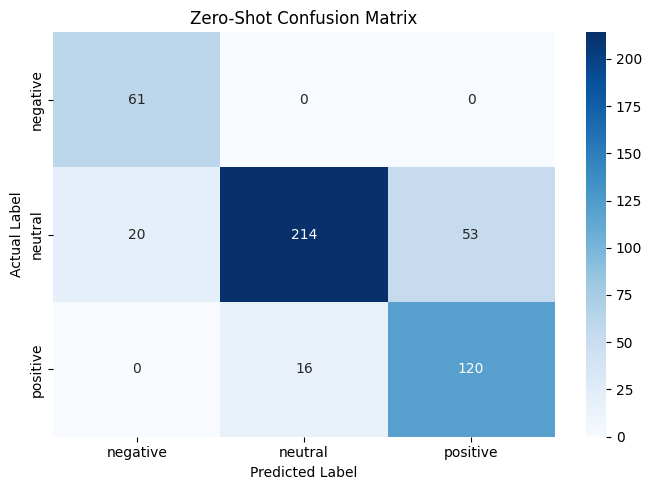


========== PREDICTION DISTRIBUTION ==========
prediction
neutral     230
positive    173
negative     81
Name: count, dtype: int64

Metrics saved successfully.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

# Load saved predictions
zero_shot_results = pd.read_csv(
    "/content/zero_shot_predictions.csv"
)

# Sort by original test index
zero_shot_results = (
    zero_shot_results
    .sort_values("test_index")
    .reset_index(drop=True)
)

# Verify alignment with the original test set
assert len(zero_shot_results) == len(test_df) == 484
assert zero_shot_results["test_index"].nunique() == 484

assert (
    zero_shot_results["true_label"].tolist()
    == test_df.reset_index(drop=True)["sentiment"].tolist()
)

y_true = zero_shot_results["true_label"]
y_pred = zero_shot_results["prediction"]

labels = ["negative", "neutral", "positive"]

# Overall metrics
accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=labels,
    zero_division=0
)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
)

print("========== ZERO-SHOT RESULTS ==========")
print(f"Accuracy:          {accuracy:.4f}")
print(f"Macro Precision:   {macro_precision:.4f}")
print(f"Macro Recall:      {macro_recall:.4f}")
print(f"Macro F1:          {macro_f1:.4f}")
print(f"Weighted F1:       {weighted_f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_true,
        y_pred,
        labels=labels,
        zero_division=0,
        digits=4
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Zero-Shot Confusion Matrix")
plt.tight_layout()
plt.show()

# Prediction distribution
print("\n========== PREDICTION DISTRIBUTION ==========")

print(
    zero_shot_results["prediction"]
    .value_counts()
)

# Save metrics
metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1"
    ],
    "Score": [
        accuracy,
        macro_precision,
        macro_recall,
        macro_f1,
        weighted_precision,
        weighted_recall,
        weighted_f1
    ]
})

metrics_df.to_csv(
    "/content/zero_shot_metrics.csv",
    index=False
)

print("\nMetrics saved successfully.")


In [ ]:
response = requests.get(
    "https://openrouter.ai/api/v1/key",
    headers={
        "Authorization": f"Bearer {api_key}"
    },
    timeout=20
)

data = response.json()["data"]

quota = data.get("free_model_daily_requests", {})

print("Used:", quota.get("used"))
print("Daily limit:", quota.get("limit"))
print("Remaining:", quota.get("remaining"))

Used: 50
Daily limit: 50
Remaining: 0


# **Cell 9: 15 shot (few shot)**

In [ ]:
import json
import pandas as pd
import time
from openai import OpenAI
from google.colab import userdata

# Initialize OpenRouter client
client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=userdata.get("OPENROUTER_API_KEY")
)

MODEL_ID = "nvidia/nemotron-3-ultra-550b-a55b:free"

LABELS = {"positive", "negative", "neutral"}
BATCH_SIZE = 11

# Keep test data in consistent order
test_df = test_df.reset_index(drop=True)

# Select 5 examples from each class using TRAINING DATA ONLY
few_shot_examples = (
    train_df.groupby("sentiment", group_keys=False)
    .sample(n=5, random_state=42)
    [["text", "sentiment"]]
    .to_dict("records")
)

print("Model:", MODEL_ID)
print("Test sentences:", len(test_df))
print("Few-shot examples:", len(few_shot_examples))

print("\nExample distribution:")

for label in ["negative", "neutral", "positive"]:
    count = sum(
        example["sentiment"] == label
        for example in few_shot_examples
    )
    print(f"{label}: {count}")

print("\nSelected examples:")

for example in few_shot_examples:
    print(f"\n{example['sentiment']}: {example['text']}")

Model: nvidia/nemotron-3-ultra-550b-a55b:free
Test sentences: 484
Few-shot examples: 15

Example distribution:
negative: 5
neutral: 5
positive: 5

Selected examples:

negative: Operating result showed a loss of EUR 2.9 mn , while a year before , it showed a profit of EUR 0.6 mn .

negative: 18 March 2010 A leakage in the gypsum pond was detected today at the Talvivaara mine .

negative: According to Finnish petrol station chain St1 's managing director Kim Wiio , the company was forced to make purchases with rising prices in the first half of 2008 , and now consumer prices are going down almost daily due to competition .

negative: The company plans to close two of the three lines at the plant , where some 450 jobs are under threat .

negative: Finnish Suominen Corporation that makes wipes , nonwovens , and flexible packaging , expects changes in the market situation to reduce sales of Suominen 's nonwovens and wet wipes from the previously estimated volumes .

neutral: `` Fixed Mobile

In [ ]:
# Build labelled examples
examples_text = ""

for i, example in enumerate(few_shot_examples, 1):
    examples_text += (
        f"\nExample {i}:"
        f"\nText: {example['text']}"
        f"\nSentiment: {example['sentiment']}\n"
    )

SYSTEM_PROMPT = f"""
You are an expert financial news sentiment classification system.

Classify financial news sentences into exactly one of these labels:
positive, negative, neutral.

Use the following labelled examples to understand the task:

{examples_text}

Classification guidelines:
1. Consider the complete financial meaning and context.
2. Positive indicates favourable business or financial developments.
3. Negative indicates unfavourable business or financial developments.
4. Neutral indicates factual reporting without a clearly positive or negative sentiment.
5. Do not classify based only on individual positive or negative words.
6. Return exactly one lowercase label.
7. Do not provide explanations or additional text.

Return only: positive, negative, or neutral.
"""

print("Few-shot prompt created successfully!")
print("Number of examples:", len(few_shot_examples))
print("\nPrompt preview:")
print(SYSTEM_PROMPT)

Few-shot prompt created successfully!
Number of examples: 15

Prompt preview:

You are an expert financial news sentiment classification system.

Classify financial news sentences into exactly one of these labels:
positive, negative, neutral.

Use the following labelled examples to understand the task:


Example 1:
Text: Operating result showed a loss of EUR 2.9 mn , while a year before , it showed a profit of EUR 0.6 mn .
Sentiment: negative

Example 2:
Text: 18 March 2010 A leakage in the gypsum pond was detected today at the Talvivaara mine .
Sentiment: negative

Example 3:
Text: According to Finnish petrol station chain St1 's managing director Kim Wiio , the company was forced to make purchases with rising prices in the first half of 2008 , and now consumer prices are going down almost daily due to competition .
Sentiment: negative

Example 4:
Text: The company plans to close two of the three lines at the plant , where some 450 jobs are under threat .
Sentiment: negative

Example 

In [ ]:
#test the prompt with 10 validation set
pilot_texts = val_df.head(10)["text"].tolist()

for i, text in enumerate(pilot_texts, 1):

    response = client.chat.completions.create(
        model=MODEL_ID,
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": text}
        ],
        temperature=0,
        max_tokens=30,
        extra_body={
            "reasoning": {"effort": "none"}
        }
    )

    prediction = response.choices[0].message.content

    print(f"{i}. {repr(prediction)}")

1. 'negative'
2. 'neutral'
3. 'neutral'
4. 'neutral'
5. 'positive'
6. 'negative'
7. 'neutral'
8. 'neutral'
9. 'neutral'
10. 'neutral'


In [ ]:
import os
import json
import time
import pandas as pd
from openai import OpenAI
from google.colab import userdata
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

# --------------------------------------------------
# 1. INITIALIZE OPENROUTER
# --------------------------------------------------

client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=userdata.get("OPENROUTER_API_KEY")
)

MODEL_ID = "nvidia/nemotron-3-ultra-550b-a55b:free"

LABELS = {"positive", "negative", "neutral"}

BATCH_SIZE = 15

OUTPUT_FILE = "/content/nemotron_few_shot_15_predictions.csv"

METRICS_FILE = "/content/nemotron_few_shot_15_metrics.csv"

print("Model:", MODEL_ID)
print("Test samples:", len(test_df))
print("Few-shot examples:", len(few_shot_examples))

# --------------------------------------------------
# 2. VERIFY FEW-SHOT EXAMPLES
# --------------------------------------------------

assert len(few_shot_examples) == 15

for label in LABELS:
    count = sum(
        ex["sentiment"] == label
        for ex in few_shot_examples
    )
    assert count == 5

print("15 balanced examples verified!")

# --------------------------------------------------
# 3. BUILD FEW-SHOT PROMPT
# --------------------------------------------------

examples_text = ""

for i, example in enumerate(few_shot_examples, 1):

    examples_text += (
        f"\nExample {i}\n"
        f"Text: {example['text']}\n"
        f"Sentiment: {example['sentiment']}\n"
    )

SYSTEM_PROMPT = f"""
You are an expert financial news sentiment classifier.

Classify each financial news sentence into exactly one category:

positive
negative
neutral

Use the following labelled examples:

{examples_text}

Classification guidelines:

1. Positive indicates favourable business or financial developments.
2. Negative indicates unfavourable business or financial developments.
3. Neutral indicates factual reporting without clearly positive
   or negative sentiment.
4. Consider the complete financial meaning and context.
5. Do not classify based only on individual positive or negative words.
6. Preserve the original order of all input sentences.
7. Return only lowercase sentiment labels.
8. Do not provide explanations.

Return ONLY a valid JSON array containing one label per input sentence.
"""

print("Few-shot prompt created successfully!")

Model: nvidia/nemotron-3-ultra-550b-a55b:free
Test samples: 484
Few-shot examples: 15
15 balanced examples verified!
Few-shot prompt created successfully!


In [ ]:
# --------------------------------------------------
# 4. VALIDATION PILOT
# --------------------------------------------------

pilot_df = val_df.head(15).copy()

pilot_texts = pilot_df["text"].tolist()

numbered_texts = "\n".join(
    f"{i+1}. {text}"
    for i, text in enumerate(pilot_texts)
)

pilot_prompt = f"""
{SYSTEM_PROMPT}

Classify the following {len(pilot_texts)} sentences:

{numbered_texts}

Return ONLY a JSON array of exactly 15 labels.
"""

pilot_response = client.chat.completions.create(
    model=MODEL_ID,
    messages=[
        {
            "role": "user",
            "content": pilot_prompt
        }
    ],
    temperature=0,
    max_tokens=200,
    extra_body={
        "reasoning": {"effort": "none"}
    }
)

pilot_raw = pilot_response.choices[0].message.content

print("Raw response:")
print(pilot_raw)

pilot_predictions = json.loads(pilot_raw)

assert isinstance(pilot_predictions, list)
assert len(pilot_predictions) == 15

pilot_predictions = [
    p.strip().lower()
    for p in pilot_predictions
]

assert all(p in LABELS for p in pilot_predictions)

print("\nPilot successful!")
print("Input sentences:", len(pilot_texts))
print("Valid predictions:", len(pilot_predictions))

for i, prediction in enumerate(pilot_predictions, 1):
    print(f"{i}. {prediction}")

Raw response:
["negative", "neutral", "neutral", "neutral", "positive", "negative", "negative", "neutral", "neutral", "neutral", "neutral", "positive", "neutral", "neutral", "positive"]

Pilot successful!
Input sentences: 15
Valid predictions: 15
1. negative
2. neutral
3. neutral
4. neutral
5. positive
6. negative
7. negative
8. neutral
9. neutral
10. neutral
11. neutral
12. positive
13. neutral
14. neutral
15. positive


In [ ]:
# --------------------------------------------------
# 5. PREPARE TEST DATA
# --------------------------------------------------

test_df = test_df.reset_index(drop=True)

# Load checkpoint if one already exists
if os.path.exists(OUTPUT_FILE):

    results = pd.read_csv(OUTPUT_FILE)

    completed_indices = set(
        results["test_index"].astype(int)
    )

else:

    results = pd.DataFrame(columns=[
        "test_index",
        "true_label",
        "prediction",
        "raw_response"
    ])

    completed_indices = set()

remaining_df = test_df[
    ~test_df.index.isin(completed_indices)
].copy()

required_requests = (
    len(remaining_df) + BATCH_SIZE - 1
) // BATCH_SIZE

print("Completed predictions:", len(results))
print("Remaining sentences:", len(remaining_df))
print("Required API requests:", required_requests)

# Do not start if the quota is insufficient.
# Check the live remaining quota after the pilot.

Completed predictions: 0
Remaining sentences: 484
Required API requests: 33


In [ ]:
# --------------------------------------------------
# 6. FULL FEW-SHOT BATCH INFERENCE
# --------------------------------------------------

for start in range(0, len(remaining_df), BATCH_SIZE):

    batch = remaining_df.iloc[
        start:start + BATCH_SIZE
    ]

    batch_texts = batch["text"].tolist()

    print("\n" + "=" * 50)
    print(
        f"Processing indices "
        f"{batch.index[0]} to {batch.index[-1]}"
    )

    numbered_texts = "\n".join(
        f"{i+1}. {text}"
        for i, text in enumerate(batch_texts)
    )

    batch_prompt = f"""
{SYSTEM_PROMPT}

Classify the following {len(batch_texts)} sentences:

{numbered_texts}

Return ONLY a JSON array containing exactly
{len(batch_texts)} lowercase labels.
Preserve the original order.
"""

    try:

        response = client.chat.completions.create(
            model=MODEL_ID,
            messages=[
                {
                    "role": "user",
                    "content": batch_prompt
                }
            ],
            temperature=0,
            max_tokens=200,
            extra_body={
                "reasoning": {"effort": "none"}
            }
        )

        raw_output = response.choices[0].message.content

        predictions = json.loads(raw_output)

        if not isinstance(predictions, list):
            raise ValueError("Response is not a JSON list")

        if len(predictions) != len(batch):
            raise ValueError(
                f"Expected {len(batch)} labels, "
                f"received {len(predictions)}"
            )

        predictions = [
            p.strip().lower()
            if isinstance(p, str) else ""
            for p in predictions
        ]

        if not all(p in LABELS for p in predictions):
            raise ValueError("Invalid sentiment labels")

        new_rows = pd.DataFrame({
            "test_index": batch.index.tolist(),
            "true_label": batch["sentiment"].tolist(),
            "prediction": predictions,
            "raw_response": [raw_output] * len(batch)
        })

        results = pd.concat(
            [results, new_rows],
            ignore_index=True
        )

        # Save immediately after every successful batch
        results.to_csv(OUTPUT_FILE, index=False)

        print("Batch successful!")
        print("Predictions saved:", len(results), "/ 484")

        time.sleep(3)

    except Exception as e:

        print("\nBATCH FAILED!")
        print("Error:", str(e))
        print("Stopping to protect remaining quota.")
        print("Previous successful batches are saved.")

        break


print("\n" + "=" * 50)
print("INFERENCE STATUS")
print("Completed:", len(results))
print("Remaining:", 484 - len(results))
print("File:", OUTPUT_FILE)


Processing indices 0 to 14
Batch successful!
Predictions saved: 15 / 484

Processing indices 15 to 29
Batch successful!
Predictions saved: 30 / 484

Processing indices 30 to 44
Batch successful!
Predictions saved: 45 / 484

Processing indices 45 to 59
Batch successful!
Predictions saved: 60 / 484

Processing indices 60 to 74
Batch successful!
Predictions saved: 75 / 484

Processing indices 75 to 89
Batch successful!
Predictions saved: 90 / 484

Processing indices 90 to 104
Batch successful!
Predictions saved: 105 / 484

Processing indices 105 to 119
Batch successful!
Predictions saved: 120 / 484

Processing indices 120 to 134
Batch successful!
Predictions saved: 135 / 484

Processing indices 135 to 149
Batch successful!
Predictions saved: 150 / 484

Processing indices 150 to 164
Batch successful!
Predictions saved: 165 / 484

Processing indices 165 to 179
Batch successful!
Predictions saved: 180 / 484

Processing indices 180 to 194
Batch successful!
Predictions saved: 195 / 484

Proce

In [ ]:
# --------------------------------------------------
# 7. VERIFY PREDICTIONS
# --------------------------------------------------

results = pd.read_csv(OUTPUT_FILE)

print("Total predictions:", len(results))
print("Unique test indices:", results["test_index"].nunique())
print("Missing predictions:", results["prediction"].isna().sum())

print("\nPrediction distribution:")
print(results["prediction"].value_counts())

assert len(results) == 484
assert results["test_index"].nunique() == 484
assert results["prediction"].isin(LABELS).all()
assert results["prediction"].notna().all()

print("\nAll verification checks passed!")

Total predictions: 484
Unique test indices: 484
Missing predictions: 0

Prediction distribution:
prediction
neutral     265
positive    137
negative     82
Name: count, dtype: int64

All verification checks passed!


In [ ]:
# --------------------------------------------------
# 8. EVALUATION
# --------------------------------------------------

y_true = results["true_label"]
y_pred = results["prediction"]

accuracy = accuracy_score(y_true, y_pred)

macro_p, macro_r, macro_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
)

weighted_p, weighted_r, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
)

print("\nNEMOTRON FEW-SHOT (15 EXAMPLES)")
print("-" * 50)

print(f"Accuracy:           {accuracy:.4f}")
print(f"Macro Precision:    {macro_p:.4f}")
print(f"Macro Recall:       {macro_r:.4f}")
print(f"Macro F1:           {macro_f1:.4f}")
print(f"Weighted Precision: {weighted_p:.4f}")
print(f"Weighted Recall:    {weighted_r:.4f}")
print(f"Weighted F1:        {weighted_f1:.4f}")

print("\nPER-CLASS PERFORMANCE")
print(classification_report(
    y_true,
    y_pred,
    labels=["negative", "neutral", "positive"],
    zero_division=0
))

print("\nCONFUSION MATRIX")

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=["negative", "neutral", "positive"]
)

print(pd.DataFrame(
    cm,
    index=["Actual negative", "Actual neutral", "Actual positive"],
    columns=[
        "Predicted negative",
        "Predicted neutral",
        "Predicted positive"
    ]
))

# Save metrics
metrics_df = pd.DataFrame([{
    "Model": MODEL_ID,
    "Method": "Few-shot (15 examples)",
    "Accuracy": accuracy,
    "Macro Precision": macro_p,
    "Macro Recall": macro_r,
    "Macro F1": macro_f1,
    "Weighted Precision": weighted_p,
    "Weighted Recall": weighted_r,
    "Weighted F1": weighted_f1
}])

metrics_df.to_csv(METRICS_FILE, index=False)

print("\nMetrics saved successfully!")


NEMOTRON FEW-SHOT (15 EXAMPLES)
--------------------------------------------------
Accuracy:           0.8450
Macro Precision:    0.8138
Macro Recall:       0.8781
Macro F1:           0.8392
Weighted Precision: 0.8521
Weighted Recall:    0.8450
Weighted F1:        0.8454

PER-CLASS PERFORMANCE
              precision    recall  f1-score   support

    negative       0.74      1.00      0.85        61
     neutral       0.90      0.83      0.87       287
    positive       0.80      0.80      0.80       136

    accuracy                           0.85       484
   macro avg       0.81      0.88      0.84       484
weighted avg       0.85      0.85      0.85       484


CONFUSION MATRIX
                 Predicted negative  Predicted neutral  Predicted positive
Actual negative                  61                  0                   0
Actual neutral                   20                239                  28
Actual positive                   1                 26                 109

Metr